# EDA longitudinal de propensión de conversión

**Unidad observacional:** cliente–mes  
**Entrenamiento:** enero–noviembre de 2026  
**Test:** diciembre de 2026  
**Objetivo:** `objetivo = 1` indica la **primera conversión** del cliente en ese mes.

Este análisis no presupone que un dato completo sea un dato coherente. Se auditan por separado:

1. estructura, llaves, tipos, faltantes y duplicados;
2. rangos y plausibilidad semántica;
3. consistencia longitudinal dentro de cada cliente;
4. relaciones entre predictores y con la conversión;
5. estabilidad temporal y traslado de train a test;
6. riesgos de fuga de información y diseño correcto de validación.

> **Lectura estadística:** este no es un problema de clasificación i.i.d. Una fila es un periodo de exposición al riesgo. Tras el primer `1`, el cliente sale del panel; los clientes que aún no convierten están censurados a la derecha.

In [2]:
# Librerías y configuración visual reproducible.
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from scipy.stats import chi2_contingency, ks_2samp
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({
    "figure.figsize": (11, 5.5),
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

DATA_DIR = Path(".")
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
META_PATH = DATA_DIR / "metaData.csv"
SUB_PATH = DATA_DIR / "sample_submission.csv"

## 1. Carga, contrato de datos y naturaleza del problema

In [3]:
# Leemos los cuatro artefactos y comprobamos el contrato declarado.
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
metadata = pd.read_csv(META_PATH)
sample_submission = pd.read_csv(SUB_PATH)

resumen_archivos = pd.DataFrame({
    "archivo": ["train.csv", "test.csv", "sample_submission.csv", "metaData.csv"],
    "filas": [len(train), len(test), len(sample_submission), len(metadata)],
    "columnas": [train.shape[1], test.shape[1], sample_submission.shape[1], metadata.shape[1]],
})
display(resumen_archivos)
display(metadata)

,archivo,filas,columnas
0,train.csv,110100,25
1,test.csv,9900,24
2,sample_submission.csv,9900,2
3,metaData.csv,26,4


,column_name,description,type,notes
0,id_cliente,Identificador único del cliente,int,Un cliente puede aparecer en varios meses y si...
1,mes,Mes calendario en formato AAAAMM,int,El split temporal se realiza por ventana mensu...
2,edad,Edad del cliente,int,Variable numérica
3,ingresos,Ingresos anuales,float,Variable numérica
4,ratio_deuda_ingresos,Ratio de deuda sobre ingresos,float,Variable numérica
5,antiguedad_cuenta_meses,Antigüedad de la cuenta del cliente en meses,int,Variable numérica
6,numero_productos,Número de productos bancarios activos del cliente,int,Variable numérica
7,saldo_promedio,Saldo promedio de la cuenta,float,Variable numérica
8,dias_ultima_transaccion,Días desde la última transacción,int,Variable numérica
9,ocupacion,Categoría laboral del cliente,string,Variable categórica


In [4]:
# Validaciones del esquema esperado. Un fallo aquí detiene el EDA en vez de ocultar el problema.
assert set(test.columns) == set(train.columns) - {"objetivo"}
assert list(sample_submission.columns) == ["id_cliente", "prediccion"]
assert len(test) == len(sample_submission)
assert sample_submission["id_cliente"].equals(test["id_cliente"])

schema = pd.DataFrame({
    "dtype_train": train.dtypes.astype(str),
    "n_unicos_train": train.nunique(dropna=False),
    "nulos_train": train.isna().sum(),
    "nulos_test": test.isna().sum().reindex(train.columns),
})
display(schema)

,dtype_train,n_unicos_train,nulos_train,nulos_test
id_cliente,int64,24628,0,0.0000
mes,int64,11,0,0.0000
edad,int64,50,0,0.0000
ingresos,float64,24232,0,0.0000
ratio_deuda_ingresos,float64,24582,0,0.0000
antiguedad_cuenta_meses,int64,179,0,0.0000
numero_productos,int64,5,0,0.0000
saldo_promedio,float64,22985,0,0.0000
dias_ultima_transaccion,int64,364,0,0.0000
ocupacion,object,5,0,0.0000


### Qué representa realmente `objetivo`

`objetivo` no dice si el cliente *alguna vez* será conversor. Indica si su primera conversión sucede durante el mes de esa fila. Por tanto:

- varios ceros del mismo cliente son periodos previos al evento, no negativos independientes;
- el último cero de entrenamiento puede ser censura, no un “no conversor” definitivo;
- la probabilidad modelada es un **hazard mensual** condicionado a seguir activo y sin conversión;
- el orden temporal debe respetarse al validar.

In [5]:
# Creamos una vista longitudinal conjunta. El test se usa solo para estudiar covariables.
panel = pd.concat(
    [train.assign(_split="train"), test.assign(objetivo=np.nan, _split="test")],
    ignore_index=True,
)
panel["fecha"] = pd.to_datetime(panel["mes"].astype(str), format="%Y%m")
panel = panel.sort_values(["id_cliente", "fecha"]).reset_index(drop=True)

grupo_cliente = panel.groupby("id_cliente", sort=False)
panel["meses_previos_observados"] = grupo_cliente.cumcount()
panel["primer_mes"] = grupo_cliente["mes"].transform("min")
panel["ultimo_mes"] = grupo_cliente["mes"].transform("max")
panel["es_primera_observacion"] = panel["mes"].eq(panel["primer_mes"])

clientes_train = set(train["id_cliente"])
clientes_test = set(test["id_cliente"])
panorama = pd.Series({
    "filas train": len(train),
    "filas test": len(test),
    "clientes únicos train": train["id_cliente"].nunique(),
    "clientes únicos test": test["id_cliente"].nunique(),
    "clientes presentes en train y test": len(clientes_train & clientes_test),
    "clientes nuevos en diciembre": len(clientes_test - clientes_train),
    "conversiones observadas": int(train["objetivo"].sum()),
    "tasa por fila": train["objetivo"].mean(),
}, name="valor")
display(panorama.to_frame())

,valor
filas train,"110,100.0000"
filas test,"9,900.0000"
clientes únicos train,"24,628.0000"
clientes únicos test,"9,900.0000"
clientes presentes en train y test,"8,061.0000"
clientes nuevos en diciembre,"1,839.0000"
conversiones observadas,"16,567.0000"
tasa por fila,0.1505


## 2. Calidad estructural: completitud, unicidad y cobertura temporal

In [6]:
# Chequeos de llaves, duplicados, valores faltantes y dominio del target.
calidad = pd.Series({
    "nulos train": int(train.isna().sum().sum()),
    "nulos test": int(test.isna().sum().sum()),
    "duplicados exactos train": int(train.duplicated().sum()),
    "duplicados exactos test": int(test.duplicated().sum()),
    "llaves cliente-mes duplicadas train": int(train.duplicated(["id_cliente", "mes"]).sum()),
    "llaves cliente-mes duplicadas test": int(test.duplicated(["id_cliente", "mes"]).sum()),
    "valores objetivo fuera de {0,1}": int((~train["objetivo"].isin([0, 1])).sum()),
}, name="cantidad")
display(calidad.to_frame())

mensual = train.groupby("mes").agg(
    filas=("id_cliente", "size"),
    clientes=("id_cliente", "nunique"),
    conversiones=("objetivo", "sum"),
    tasa_conversion=("objetivo", "mean"),
)
display(mensual)

,cantidad
nulos train,0
nulos test,0
duplicados exactos train,0
duplicados exactos test,0
llaves cliente-mes duplicadas train,0
llaves cliente-mes duplicadas test,0
"valores objetivo fuera de {0,1}",0


,filas,clientes,conversiones,tasa_conversion
mes,,,,
202601,10400,10400,1521,0.1462
202602,9800,9800,1543,0.1574
202603,10300,10300,1527,0.1483
202604,9600,9600,1473,0.1534
202605,10100,10100,1584,0.1568
202606,10350,10350,1600,0.1546
202607,9700,9700,1410,0.1454
202608,10050,10050,1449,0.1442
202609,9900,9900,1393,0.1407


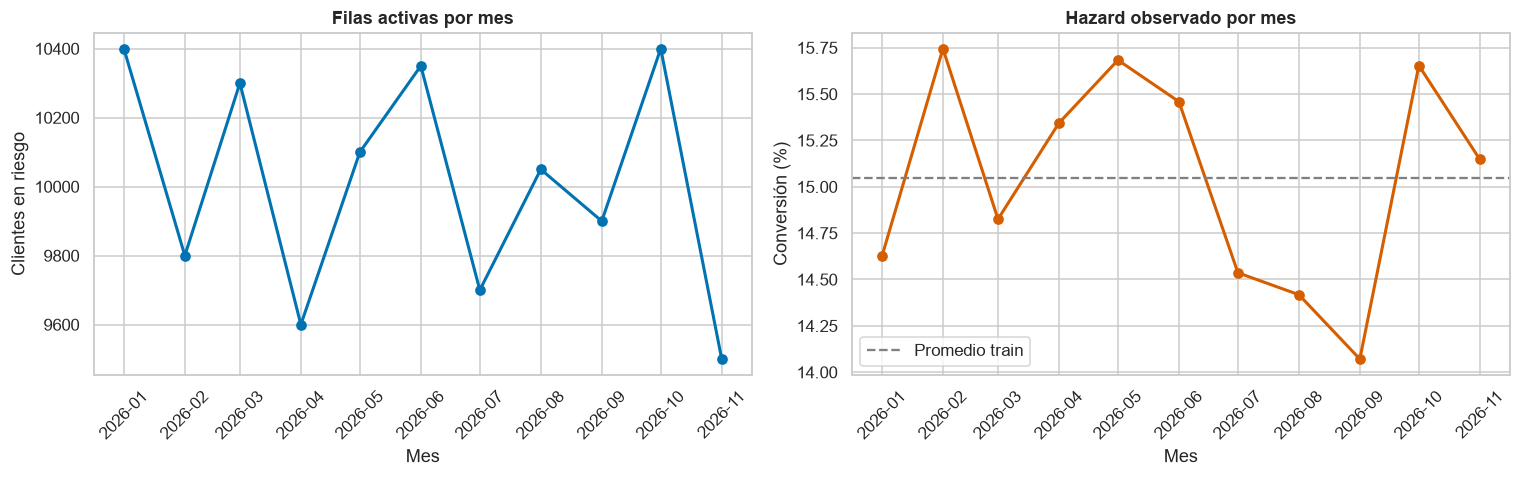

In [7]:
# Volumen y tasa se separan en dos paneles para no mezclar escalas.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = pd.to_datetime(mensual.index.astype(str), format="%Y%m")

axes[0].plot(x, mensual["filas"], marker="o", linewidth=2)
axes[0].set(title="Filas activas por mes", xlabel="Mes", ylabel="Clientes en riesgo")
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(x, mensual["tasa_conversion"] * 100, marker="o", linewidth=2, color="#D55E00")
axes[1].axhline(train["objetivo"].mean() * 100, ls="--", color="grey", label="Promedio train")
axes[1].set(title="Hazard observado por mes", xlabel="Mes", ylabel="Conversión (%)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Integridad del proceso de primera conversión

In [8]:
# Verificamos las reglas esenciales de un evento terminal.
eventos_por_cliente = train.groupby("id_cliente")["objetivo"].sum()
positivos = train.loc[train["objetivo"].eq(1), ["id_cliente", "mes"]]
apariciones = panel[["id_cliente", "mes"]]
despues_evento = positivos.merge(apariciones, on="id_cliente", suffixes=("_evento", "_observacion"))

reglas_evento = pd.Series({
    "clientes con más de una conversión": int(eventos_por_cliente.gt(1).sum()),
    "filas posteriores a una conversión": int(
        (despues_evento["mes_observacion"] > despues_evento["mes_evento"]).sum()
    ),
    "clientes que convirtieron en train": int(eventos_por_cliente.eq(1).sum()),
    "clientes train censurados sin evento": int(eventos_por_cliente.eq(0).sum()),
}, name="cantidad")
display(reglas_evento.to_frame())

# Los saltos se miden en índices mensuales para no restar enteros AAAAMM.
indice_mes = panel["fecha"].dt.year * 12 + panel["fecha"].dt.month
saltos = indice_mes.groupby(panel["id_cliente"]).diff()
display(pd.Series({
    "pares consecutivos": int(saltos.eq(1).sum()),
    "huecos > 1 mes": int(saltos.gt(1).sum()),
    "saltos no positivos": int(saltos.le(0).sum()),
}, name="cantidad").to_frame())

,cantidad
clientes con más de una conversión,0
filas posteriores a una conversión,0
clientes que convirtieron en train,16567
clientes train censurados sin evento,8061


,cantidad
pares consecutivos,93533
huecos > 1 mes,0
saltos no positivos,0


,entradas,salidas
202601,10400,1521
202602,921,1543
202603,2043,1527
202604,827,1473
202605,1973,1584
202606,1834,1600
202607,950,1410
202608,1760,1449
202609,1299,1393
202610,1893,1628


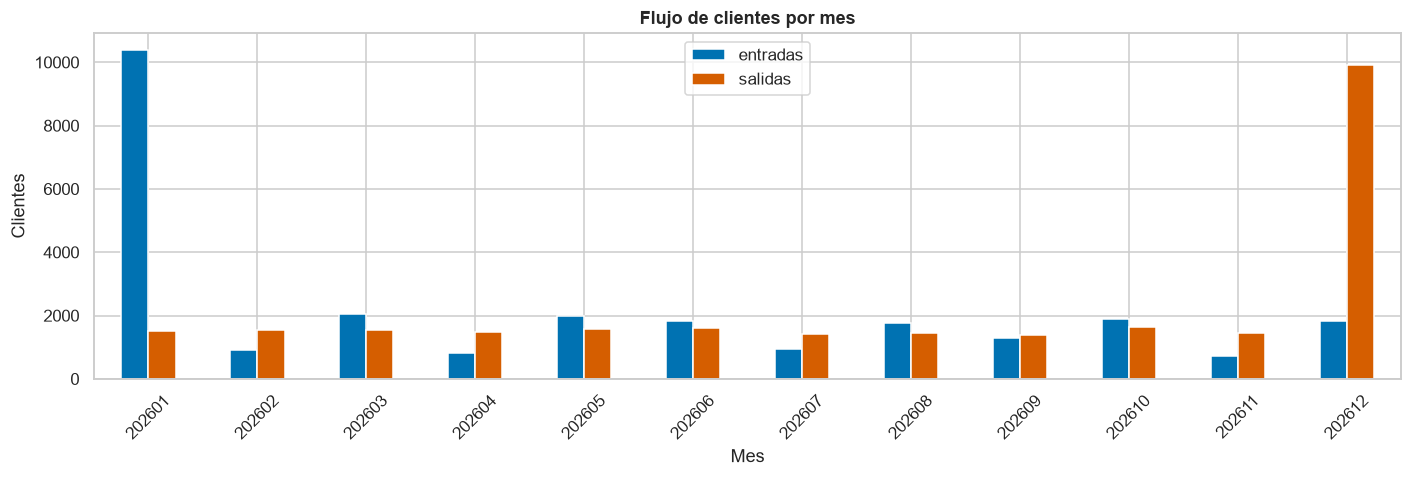

In [9]:
# Entradas y salidas del panel. Las salidas de ene-nov coinciden con conversiones.
historia = panel.groupby("id_cliente").agg(
    primer_mes=("mes", "min"), ultimo_mes=("mes", "max"), n_meses=("mes", "size")
)
entradas = historia["primer_mes"].value_counts().sort_index()
salidas = historia["ultimo_mes"].value_counts().sort_index()
flujo = pd.concat([entradas.rename("entradas"), salidas.rename("salidas")], axis=1).fillna(0)
display(flujo.astype(int))

ax = flujo.plot(kind="bar", figsize=(13, 4.5), color=["#0072B2", "#D55E00"])
ax.set(title="Flujo de clientes por mes", xlabel="Mes", ylabel="Clientes")
ax.legend(title="")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** el panel es perfectamente contiguo: no hay reingresos ni huecos. Hasta noviembre, cada salida corresponde al evento. Diciembre contiene tanto sobrevivientes como una cohorte nueva; esa mezcla debe reproducirse en validación.

## 4. Coherencia longitudinal: ¿las variables evolucionan como deberían?

,variable,pares,% exactamente igual,% clientes donde cambia alguna vez,mediana delta mensual,% delta = +1
0,edad,93533,100.0000,0.0000,0.0000,0.0000
1,ingresos,93533,100.0000,0.0000,0.0000,0.0000
2,ratio_deuda_ingresos,93533,100.0000,0.0000,0.0000,0.0000
3,antiguedad_cuenta_meses,93533,100.0000,0.0000,0.0000,0.0000
4,numero_productos,93533,100.0000,0.0000,0.0000,0.0000
5,saldo_promedio,93533,100.0000,0.0000,0.0000,0.0000
6,dias_ultima_transaccion,93533,100.0000,0.0000,0.0000,0.0000
7,ocupacion,93533,100.0000,0.0000,NaN,NaN
8,region,93533,100.0000,0.0000,NaN,NaN
9,canal_adquisicion,93533,100.0000,0.0000,NaN,NaN


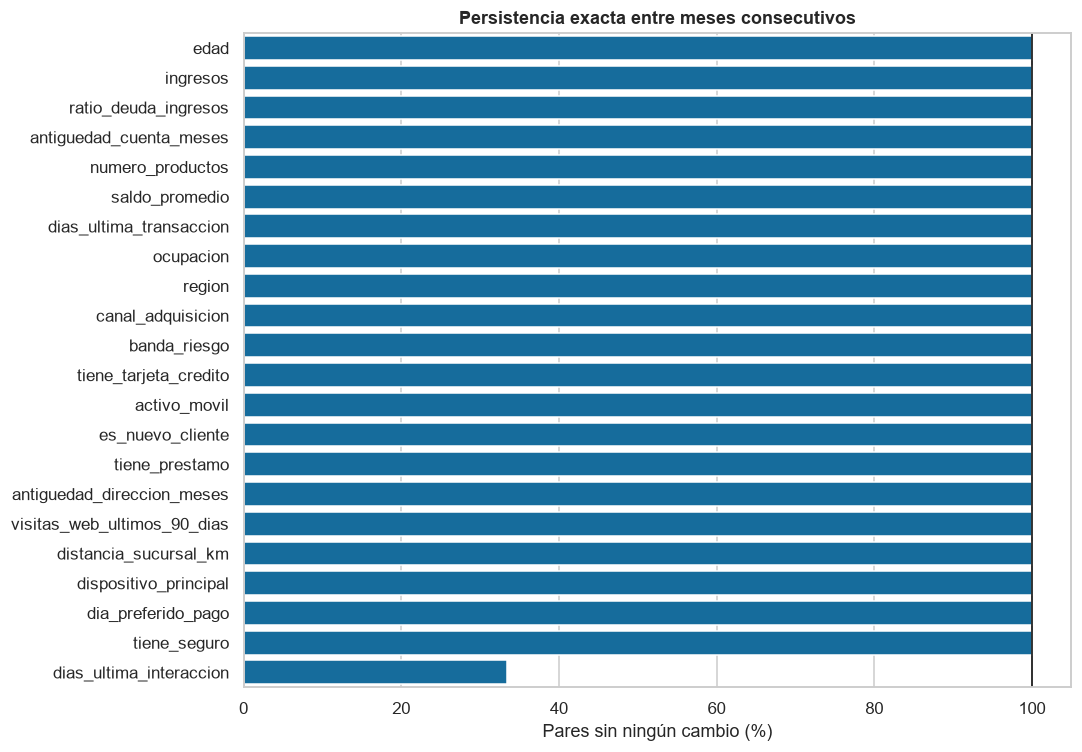

In [10]:
# Comparamos cada fila con el mes inmediatamente anterior del mismo cliente.
predictores = [c for c in test.columns if c not in ["id_cliente", "mes"]]
pares = panel.loc[saltos.eq(1)].copy()
consistencia = []

for col in predictores:
    anterior = panel.groupby("id_cliente")[col].shift().loc[pares.index]
    actual = pares[col]
    fila = {
        "variable": col,
        "pares": len(actual),
        "% exactamente igual": 100 * actual.eq(anterior).mean(),
        "% clientes donde cambia alguna vez": 100 * panel.groupby("id_cliente")[col].nunique().gt(1).mean(),
    }
    if pd.api.types.is_numeric_dtype(panel[col]) and not pd.api.types.is_bool_dtype(panel[col]):
        delta = actual.to_numpy() - anterior.to_numpy()
        fila["mediana delta mensual"] = np.nanmedian(delta)
        fila["% delta = +1"] = 100 * np.mean(delta == 1)
    consistencia.append(fila)

consistencia = pd.DataFrame(consistencia).sort_values("% exactamente igual", ascending=False)
display(consistencia)

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=consistencia, y="variable", x="% exactamente igual", ax=ax, color="#0072B2")
ax.axvline(100, color="black", lw=1)
ax.set(title="Persistencia exacta entre meses consecutivos", xlabel="Pares sin ningún cambio (%)", ylabel="")
plt.tight_layout()
plt.show()

In [11]:
# En variables de antigüedad, el incremento natural esperado sería aproximadamente +1 por mes.
variables_reloj = ["edad", "antiguedad_cuenta_meses", "antiguedad_direccion_meses"]
deltas_reloj = []
for col in variables_reloj:
    anterior = panel.groupby("id_cliente")[col].shift().loc[pares.index]
    delta = pares[col] - anterior
    deltas_reloj.append({
        "variable": col,
        "pares": len(delta),
        "% delta 0": 100 * delta.eq(0).mean(),
        "% delta +1": 100 * delta.eq(1).mean(),
        "delta mínimo": delta.min(),
        "delta máximo": delta.max(),
    })
display(pd.DataFrame(deltas_reloj))

# Comportamiento especial de recencia: igualdad con transacción y cambio mensual.
prev_interaccion = panel.groupby("id_cliente")["dias_ultima_interaccion"].shift()
recencia = pd.DataFrame({
    "posición_observada": panel["meses_previos_observados"],
    "igual_a_dias_ultima_transaccion": panel["dias_ultima_interaccion"].eq(panel["dias_ultima_transaccion"]),
    "cambia_vs_mes_anterior": panel["dias_ultima_interaccion"].ne(prev_interaccion) & panel["meses_previos_observados"].gt(0),
})
display(recencia.groupby("posición_observada").agg(
    filas=("igual_a_dias_ultima_transaccion", "size"),
    pct_igual_transaccion=("igual_a_dias_ultima_transaccion", "mean"),
    pct_cambia=("cambia_vs_mes_anterior", "mean"),
).head(12))

,variable,pares,% delta 0,% delta +1,delta mínimo,delta máximo
0,edad,93533,100.0000,0.0000,0.0000,0.0000
1,antiguedad_cuenta_meses,93533,100.0000,0.0000,0.0000,0.0000
2,antiguedad_direccion_meses,93533,100.0000,0.0000,0.0000,0.0000


,filas,pct_igual_transaccion,pct_cambia
posición_observada,,,
0,26467,0.6645,0.0000
1,20695,0.6335,0.4506
2,16874,0.5586,0.5504
3,13236,0.5124,0.6263
4,10649,0.4517,0.7081
5,8278,0.4047,0.7646
6,6758,0.3307,0.8353
7,5261,0.2883,0.8770
8,4033,0.2303,0.9122


### Hallazgo crítico

**Todos los predictores salvo `dias_ultima_interaccion` están congelados dentro del cliente.** No solo ocurre con atributos razonablemente estáticos como región: también con edad, antigüedad de cuenta, “nuevo cliente”, saldo, productos, visitas de los últimos 90 días y días desde la última transacción.

Esto indica que el archivo no es un panel operativo convencional: parece combinar un perfil fijo por cliente con una única variable parcialmente dinámica. No conviene fabricar deltas de variables congeladas; serían ceros por construcción. En cambio, sí son útiles `meses_previos_observados`, cohorte de entrada y cambios de interacción, calculados usando solo historia disponible.

## 5. Plausibilidad semántica y valores en los límites

In [12]:
# Reglas de negocio exploratorias: señalan contradicciones potenciales, no verdades universales.
reglas = {
    "antigüedad cuenta > edad en meses": panel["antiguedad_cuenta_meses"] > panel["edad"] * 12,
    "antigüedad dirección > edad en meses": panel["antiguedad_direccion_meses"] > panel["edad"] * 12,
    "nuevo cliente con cuenta > 12 meses": panel["es_nuevo_cliente"] & panel["antiguedad_cuenta_meses"].gt(12),
    "nuevo cliente persiste después de su 1er mes": panel["es_nuevo_cliente"] & panel["meses_previos_observados"].gt(0),
    "préstamo y tarjeta pero < 2 productos": panel["tiene_prestamo"] & panel["tiene_tarjeta_credito"] & panel["numero_productos"].lt(2),
    "día preferido fuera de 1..28": ~panel["dia_preferido_pago"].between(1, 28),
    "ratio deuda/ingresos fuera de [0,1]": ~panel["ratio_deuda_ingresos"].between(0, 1),
}
tabla_reglas = pd.DataFrame([
    {"regla": nombre, "filas": int(mask.sum()), "% filas": 100 * mask.mean()}
    for nombre, mask in reglas.items()
]).sort_values("% filas", ascending=False)
display(tabla_reglas)

# Detectamos acumulaciones exactas en mínimos/máximos, indicio de truncamiento o winsorización.
numericas = [
    c for c in predictores
    if pd.api.types.is_numeric_dtype(train[c]) and not pd.api.types.is_bool_dtype(train[c])
]
limites = []
for col in numericas:
    s = train[col]
    limites.append({
        "variable": col,
        "mínimo": s.min(), "% en mínimo": 100 * s.eq(s.min()).mean(),
        "máximo": s.max(), "% en máximo": 100 * s.eq(s.max()).mean(),
        "p01": s.quantile(.01), "p99": s.quantile(.99),
    })
display(pd.DataFrame(limites))

,regla,filas,% filas
2,nuevo cliente con cuenta > 12 meses,21458,17.8817
4,préstamo y tarjeta pero < 2 productos,18817,15.6808
3,nuevo cliente persiste después de su 1er mes,17977,14.9808
1,antigüedad dirección > edad en meses,0,0.0000
0,antigüedad cuenta > edad en meses,0,0.0000
5,día preferido fuera de 1..28,0,0.0000
6,"ratio deuda/ingresos fuera de [0,1]",0,0.0000


,variable,mínimo,% en mínimo,máximo,% en máximo,p01,p99
0,edad,22.0000,1.8719,71.0000,1.9237,22.0000,71.0000
1,ingresos,"18,000.0000",1.6322,"145,700.0727",0.0036,"18,000.0000","116,247.4440"
2,ratio_deuda_ingresos,0.0200,0.1526,0.9500,0.0272,0.0442,0.7716
3,antiguedad_cuenta_meses,1.0000,0.4968,179.0000,0.5840,2.0000,178.0000
4,numero_productos,1.0000,45.6649,5.0000,3.2171,1.0000,5.0000
5,saldo_promedio,300.0000,6.8574,"90,000.0000",0.0018,300.0000,"65,552.5396"
6,dias_ultima_transaccion,1.0000,0.1853,364.0000,0.3161,4.0000,361.0000
7,antiguedad_direccion_meses,1.0000,0.4205,239.0000,0.4360,3.0000,237.0000
8,visitas_web_ultimos_90_dias,0.0000,0.0436,26.0000,0.0009,2.0000,15.0000
9,distancia_sucursal_km,0.2125,0.0054,80.0000,0.1408,1.1777,47.9389


**Quirks semánticos:** `es_nuevo_cliente` no guarda relación con la antigüedad de cuenta y permanece activo durante varios meses. Además, “número de productos” no parece contar de forma aditiva tarjeta y préstamo. Deben tratarse como etiquetas sintéticas/operacionales, no imponerles una interpretación contable no documentada. Hay masas en límites exactos (especialmente saldo = 300 e ingresos = 18,000), compatibles con truncamiento.

## 6. Distribuciones univariadas y cobertura de train/test

In [13]:
# Resumen robusto con percentiles; la media sola ocultaría colas y clipping.
percentiles = [.001, .01, .05, .25, .5, .75, .95, .99, .999]
display(train[numericas].describe(percentiles=percentiles).T)

,count,mean,std,min,0.1%,1%,5%,25%,50%,75%,95%,99%,99.9%,max
edad,"110,100.0000",46.3590,14.3476,22.0000,22.0000,22.0000,24.0000,34.0000,46.0000,59.0000,69.0000,71.0000,71.0000,71.0000
ingresos,"110,100.0000","65,162.4599","21,740.9950","18,000.0000","18,000.0000","18,000.0000","28,557.4643","50,148.6205","64,858.0115","79,838.1435","101,190.4011","116,247.4440","131,638.0473","145,700.0727"
ratio_deuda_ingresos,"110,100.0000",0.3294,0.1669,0.0200,0.0200,0.0442,0.0902,0.2015,0.3106,0.4385,0.6313,0.7716,0.9092,0.9500
antiguedad_cuenta_meses,"110,100.0000",88.8984,51.5237,1.0000,1.0000,2.0000,9.0000,44.0000,88.0000,133.0000,170.0000,178.0000,179.0000,179.0000
numero_productos,"110,100.0000",1.9231,1.0740,1.0000,1.0000,1.0000,1.0000,1.0000,2.0000,3.0000,4.0000,5.0000,5.0000,5.0000
saldo_promedio,"110,100.0000","26,294.2463","16,035.5850",300.0000,300.0000,300.0000,300.0000,"14,487.4274","25,692.0246","37,264.0604","54,217.1707","65,552.5396","79,504.1809","90,000.0000"
dias_ultima_transaccion,"110,100.0000",190.2450,104.9507,1.0000,1.0000,4.0000,21.0000,101.0000,194.0000,282.0000,348.0000,361.0000,364.0000,364.0000
antiguedad_direccion_meses,"110,100.0000",119.9592,68.7949,1.0000,1.0000,3.0000,13.0000,61.0000,120.0000,179.0000,227.0000,237.0000,239.0000,239.0000
visitas_web_ultimos_90_dias,"110,100.0000",8.0120,2.8074,0.0000,1.0000,2.0000,4.0000,6.0000,8.0000,10.0000,13.0000,15.0000,18.0000,26.0000
distancia_sucursal_km,"110,100.0000",10.1578,9.1988,0.2125,0.6760,1.1777,2.0001,4.3309,7.4870,12.7180,27.0643,47.9389,80.0000,80.0000


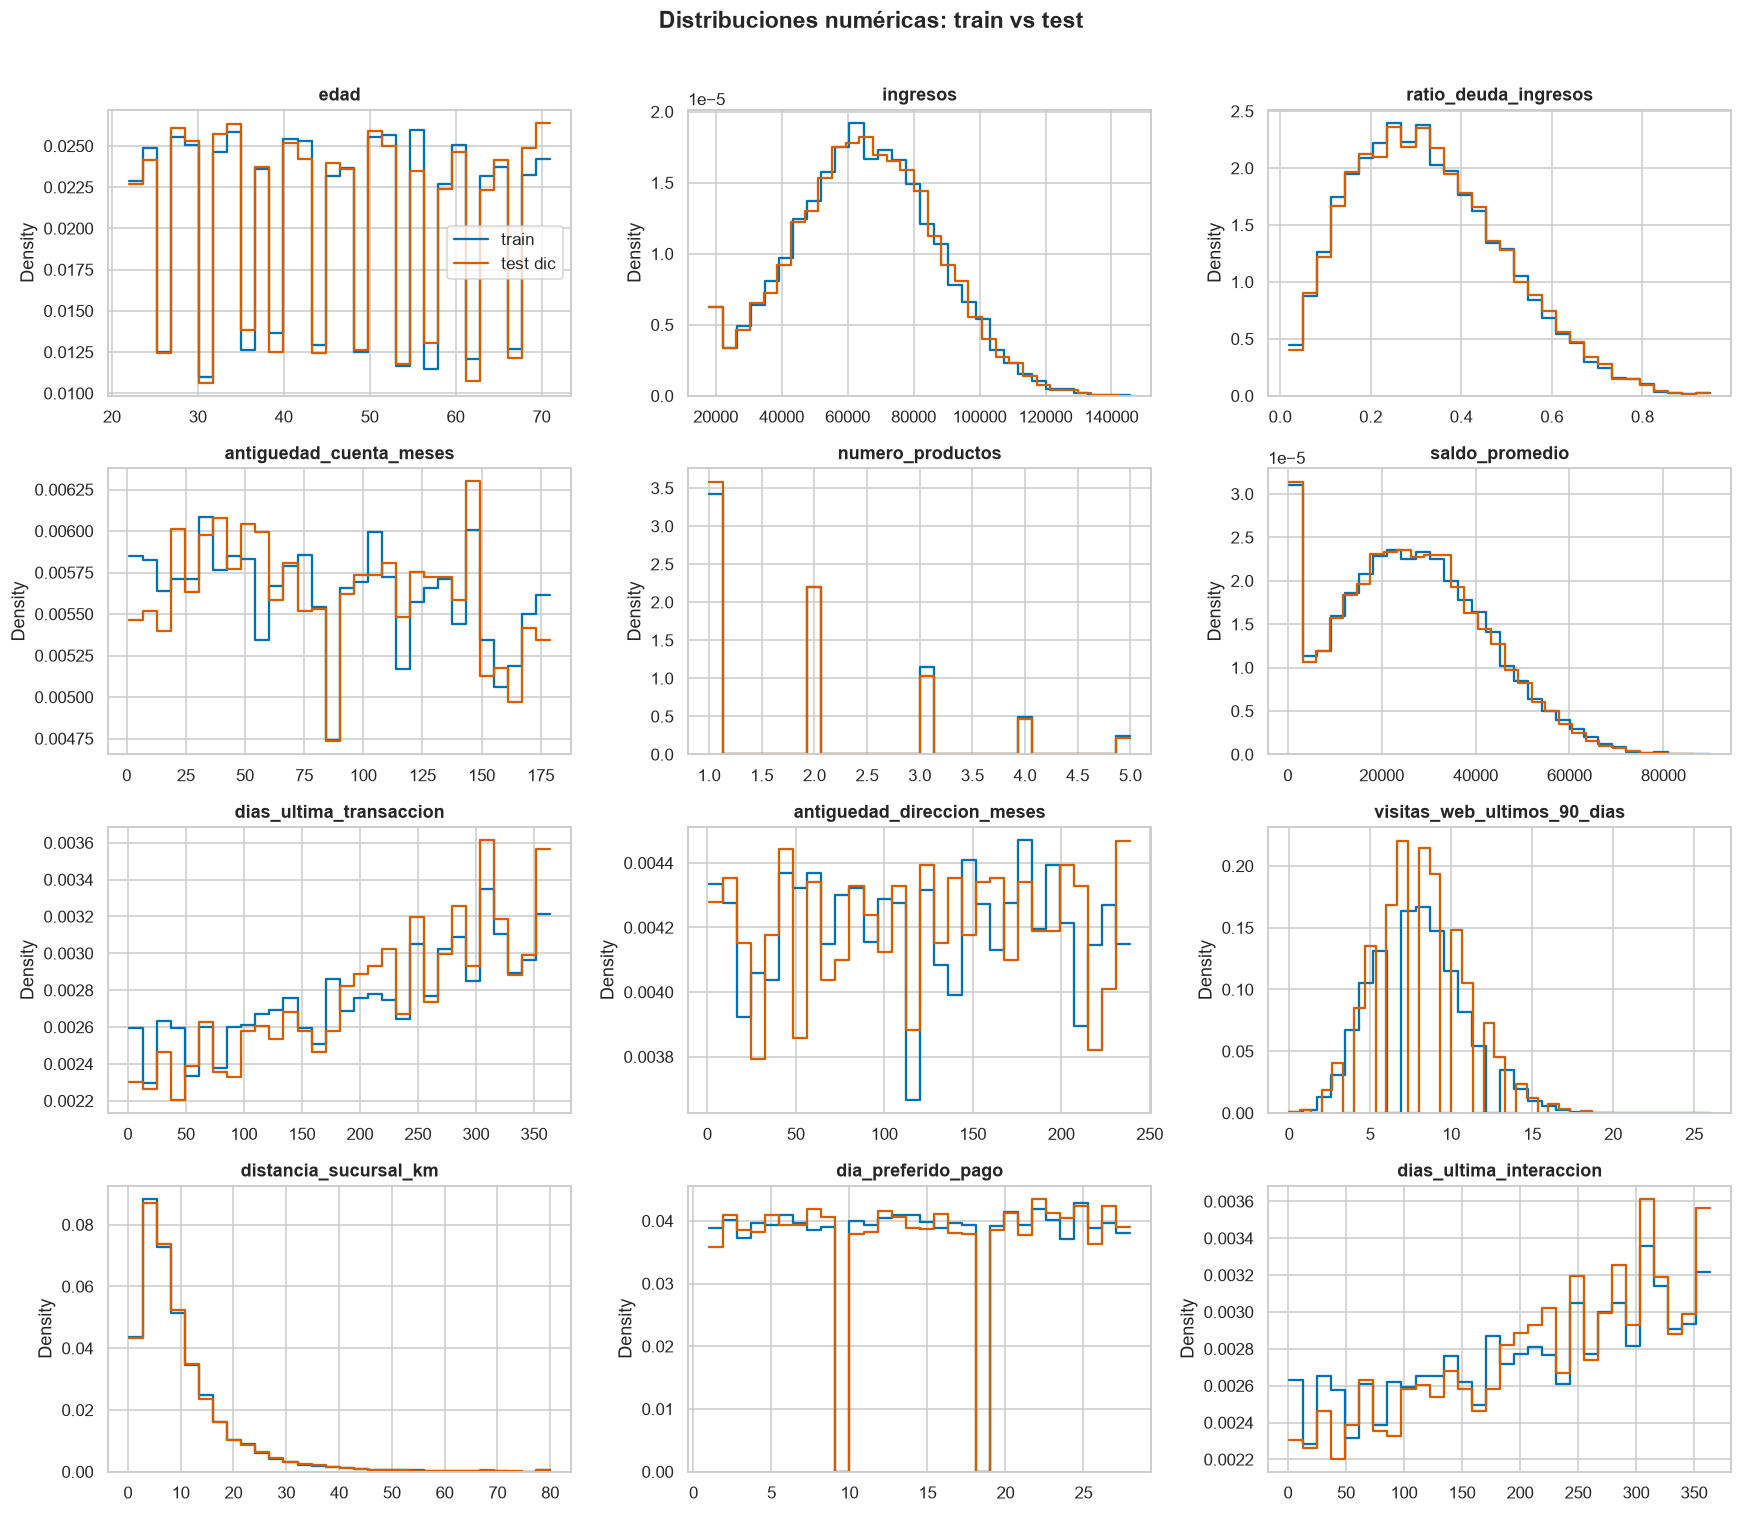

In [14]:
# Histogramas normalizados: train completo frente a diciembre.
ncols = 3
nrows = int(np.ceil(len(numericas) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.4 * nrows))
axes = np.ravel(axes)
for ax, col in zip(axes, numericas):
    sns.histplot(train[col], bins=30, stat="density", element="step", fill=False,
                 color="#0072B2", label="train", ax=ax)
    sns.histplot(test[col], bins=30, stat="density", element="step", fill=False,
                 color="#D55E00", label="test dic", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes[len(numericas):]:
    ax.remove()
axes[0].legend()
fig.suptitle("Distribuciones numéricas: train vs test", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

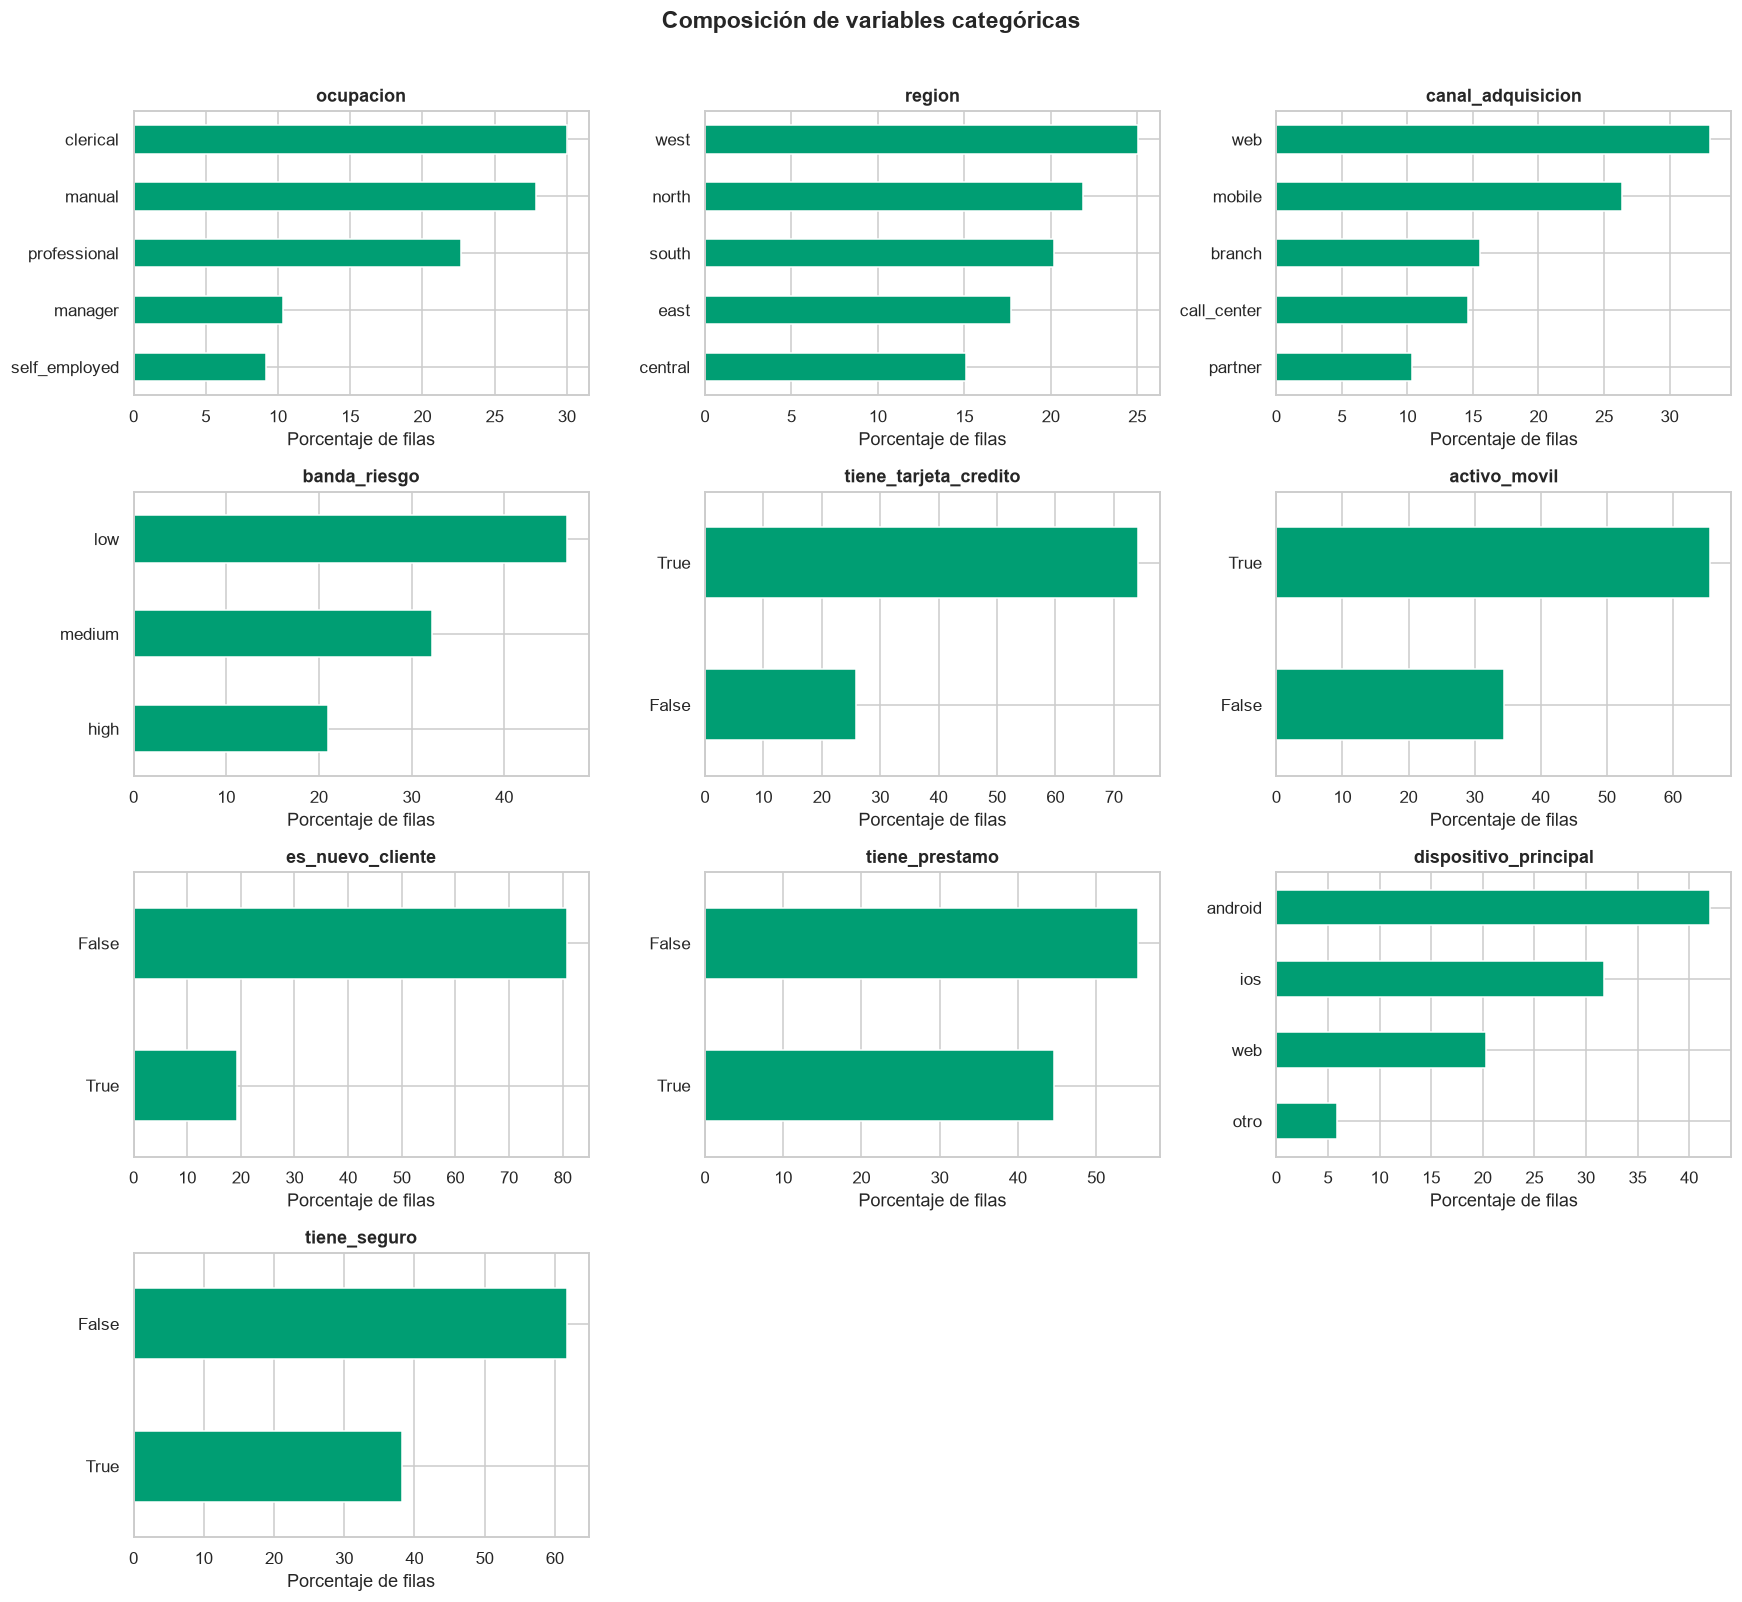

In [15]:
# Frecuencias de categorías y booleanos.
categoricas = train.select_dtypes(include=["object", "bool"]).columns.tolist()
fig, axes = plt.subplots(int(np.ceil(len(categoricas) / 3)), 3, figsize=(16, 3.6 * np.ceil(len(categoricas) / 3)))
axes = np.ravel(axes)
for ax, col in zip(axes, categoricas):
    freq = train[col].astype(str).value_counts(normalize=True).mul(100).sort_values()
    freq.plot.barh(ax=ax, color="#009E73")
    ax.set(title=col, xlabel="Porcentaje de filas", ylabel="")
for ax in axes[len(categoricas):]:
    ax.remove()
fig.suptitle("Composición de variables categóricas", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Relaciones entre variables predictoras

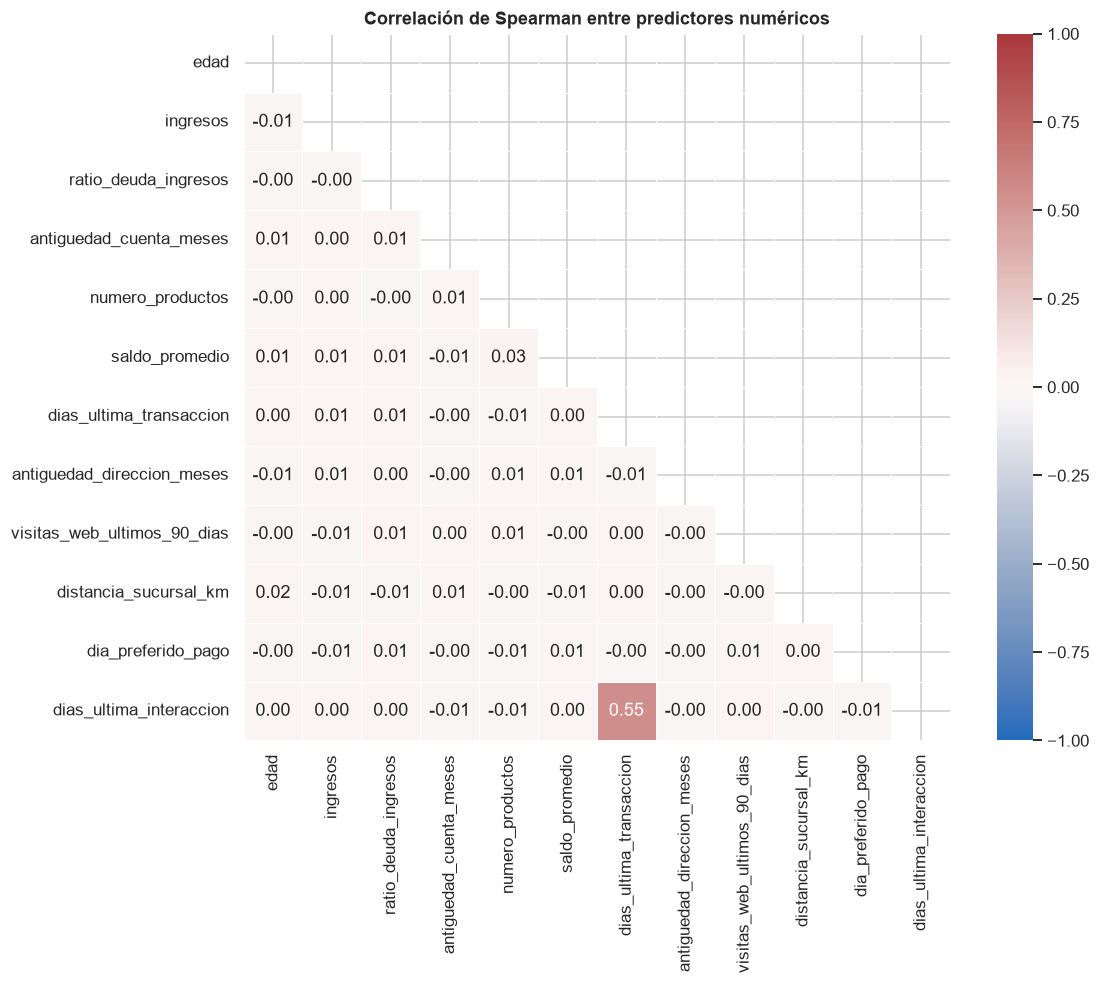

,level_0,level_1,rho,abs_rho
55,dias_ultima_transaccion,dias_ultima_interaccion,0.5528,0.5528
38,numero_productos,saldo_promedio,0.0258,0.0258
8,edad,distancia_sucursal_km,0.0164,0.0164
44,numero_productos,dias_ultima_interaccion,-0.0140,0.0140
21,ratio_deuda_ingresos,antiguedad_cuenta_meses,0.0135,0.0135
39,numero_productos,dias_ultima_transaccion,-0.0127,0.0127
18,ingresos,distancia_sucursal_km,-0.0125,0.0125
51,dias_ultima_transaccion,antiguedad_direccion_meses,-0.0116,0.0116
61,visitas_web_ultimos_90_dias,dia_preferido_pago,0.0113,0.0113
6,edad,antiguedad_direccion_meses,-0.0110,0.0110


In [16]:
# Spearman capta relaciones monótonas y es menos sensible a outliers que Pearson.
corr = train[numericas].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", square=True, linewidths=.5, ax=ax)
ax.set_title("Correlación de Spearman entre predictores numéricos")
plt.tight_layout()
plt.show()

pares_corr = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack().rename("rho").reset_index()
        .assign(abs_rho=lambda d: d["rho"].abs())
        .sort_values("abs_rho", ascending=False)
)
display(pares_corr.head(10))

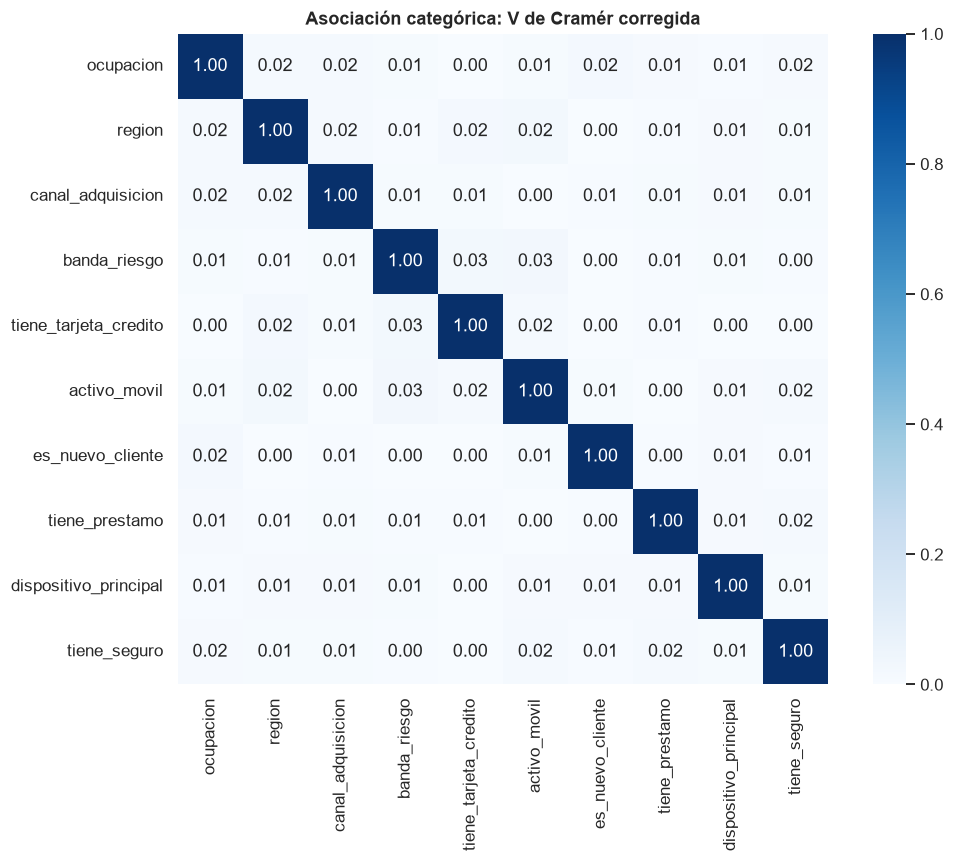

In [17]:
# V de Cramér corregida para asociaciones entre variables categóricas/booleanas.
def cramers_v(x: pd.Series, y: pd.Series) -> float:
    tabla = pd.crosstab(x.astype(str), y.astype(str))
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.to_numpy().sum()
    phi2 = chi2 / n
    r, k = tabla.shape
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / max(n - 1, 1))
    r_corr = r - ((r - 1) ** 2) / max(n - 1, 1)
    k_corr = k - ((k - 1) ** 2) / max(n - 1, 1)
    denom = min(k_corr - 1, r_corr - 1)
    return np.sqrt(phi2_corr / denom) if denom > 0 else 0.0

cram = pd.DataFrame(np.eye(len(categoricas)), index=categoricas, columns=categoricas)
for i, c1 in enumerate(categoricas):
    for c2 in categoricas[i + 1:]:
        cram.loc[c1, c2] = cram.loc[c2, c1] = cramers_v(train[c1], train[c2])

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cram, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f", square=True, ax=ax)
ax.set_title("Asociación categórica: V de Cramér corregida")
plt.tight_layout()
plt.show()

In [18]:
# Cruces interpretables para comprobar si las etiquetas de productos/riesgo son redundantes.
display(pd.crosstab(train["banda_riesgo"], train["numero_productos"], normalize="index").round(3))
display(pd.crosstab(train["es_nuevo_cliente"], train["antiguedad_cuenta_meses"].gt(12), normalize="index").round(3))

numero_productos,1,2,3,4,5
banda_riesgo,,,,,
high,0.4310,0.2950,0.1690,0.0780,0.0280
low,0.4900,0.2930,0.1330,0.0550,0.0290
medium,0.4250,0.2910,0.1730,0.0710,0.0400


antiguedad_cuenta_meses,False,True
es_nuevo_cliente,,
False,0.0690,0.9310
True,0.0680,0.9320


**Insight:** la única correlación numérica destacable es entre las dos recencias. Parte de esa relación es mecánica: `dias_ultima_interaccion` suele comenzar igual que `dias_ultima_transaccion` y luego se desacopla. El resto de asociaciones es débil; esto no garantiza utilidad predictiva, solo baja redundancia marginal.

## 8. Predictores frente al objetivo

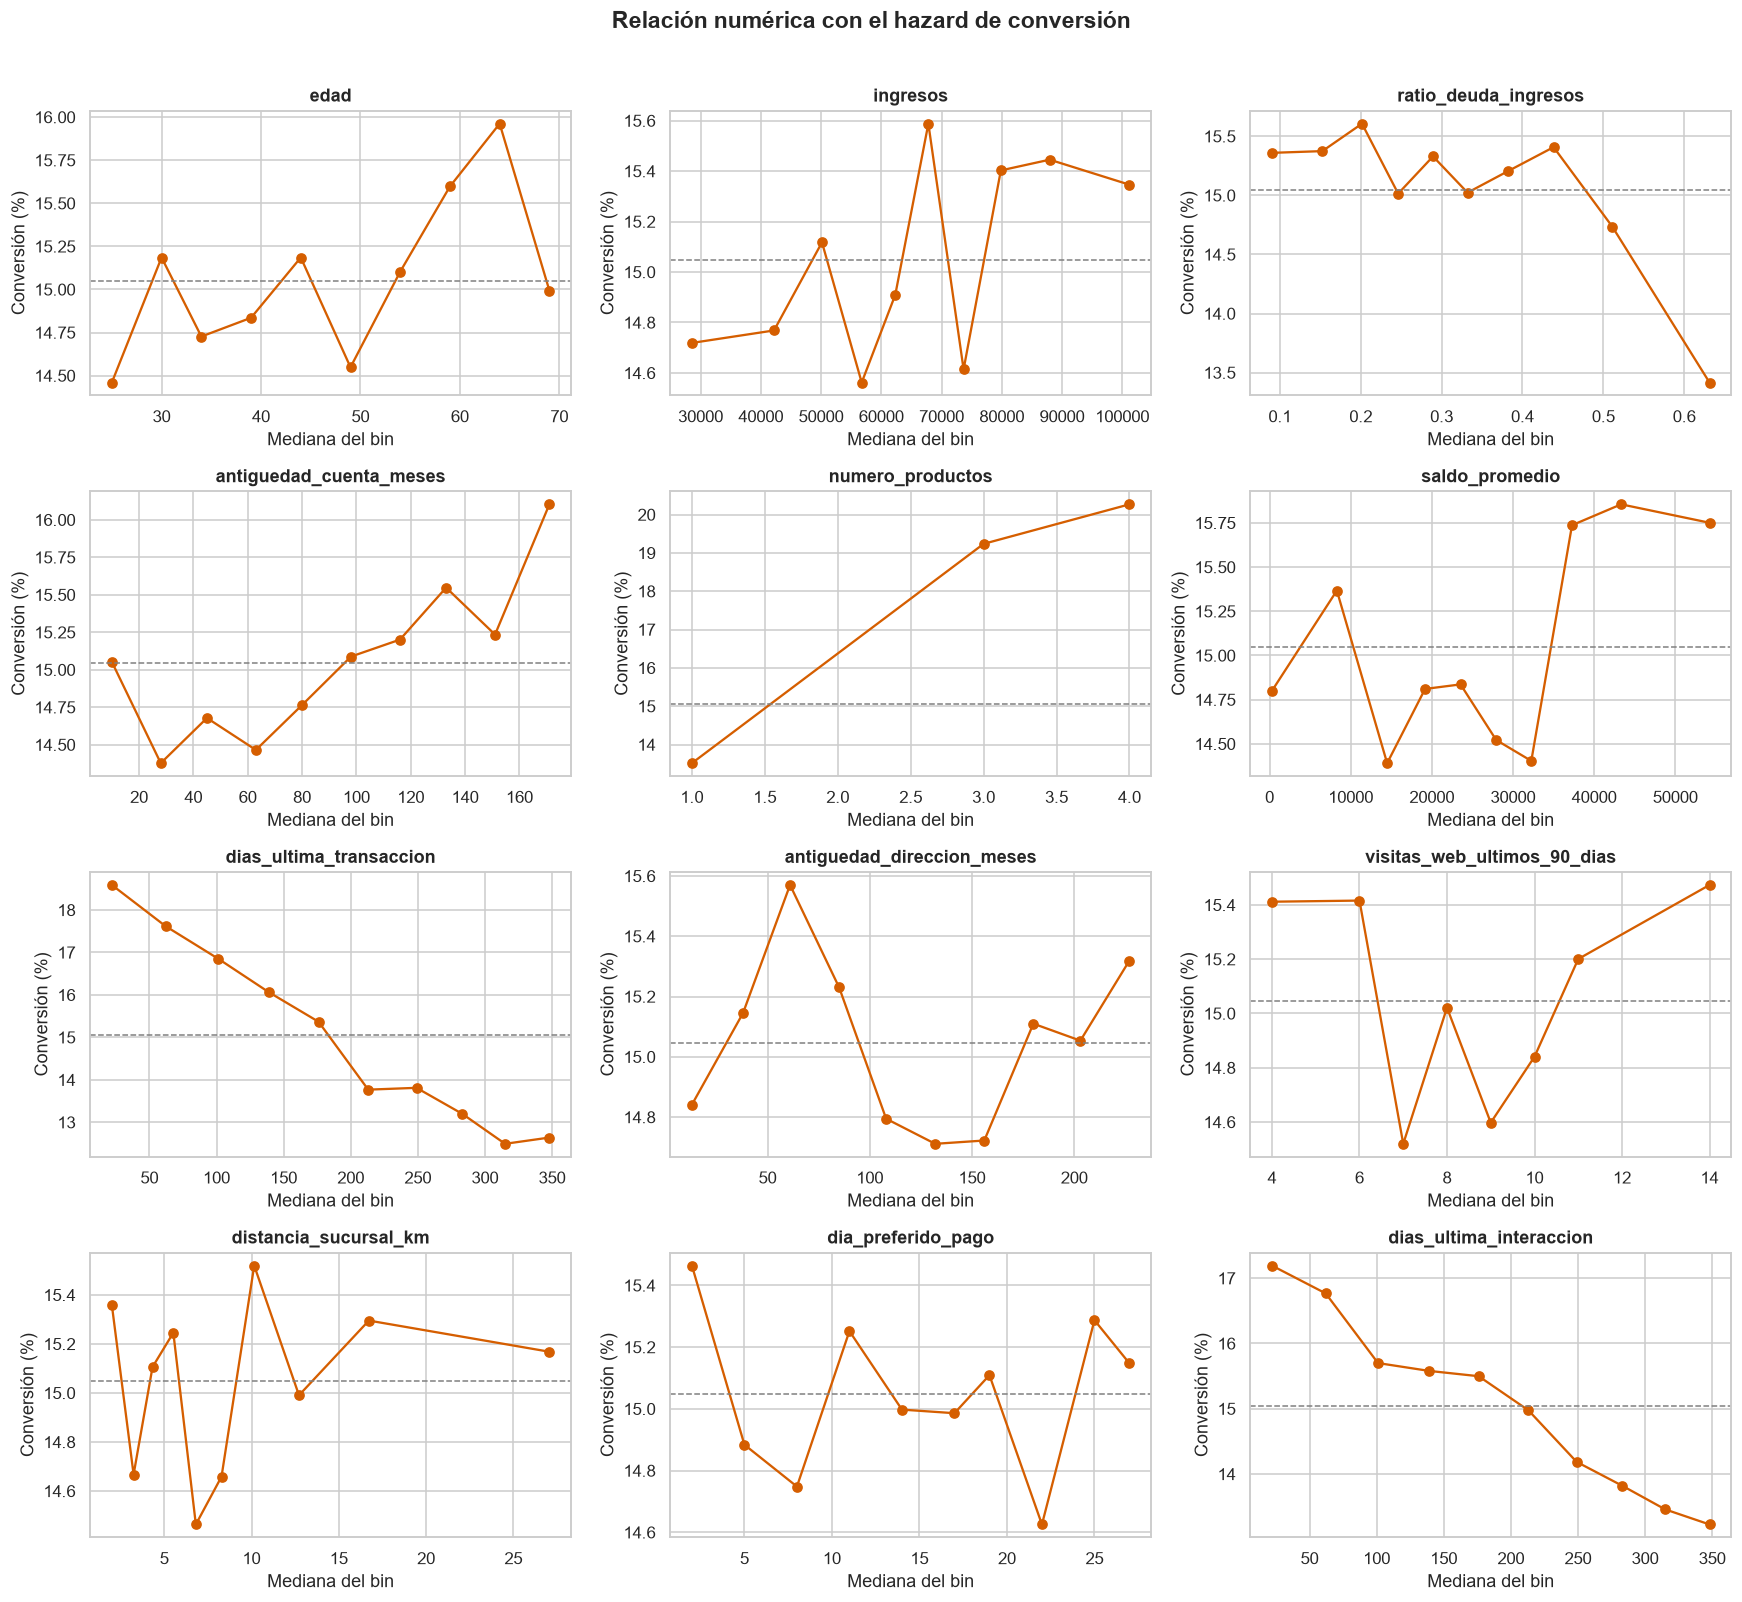

In [19]:
# Curvas de tasa por deciles. Se usa qcut con duplicates='drop' por posibles masas en límites.
fig, axes = plt.subplots(int(np.ceil(len(numericas) / 3)), 3, figsize=(16, 3.6 * np.ceil(len(numericas) / 3)))
axes = np.ravel(axes)
global_rate = train["objetivo"].mean() * 100

tabla_bines = []
for ax, col in zip(axes, numericas):
    bins = pd.qcut(train[col], q=10, duplicates="drop")
    tmp = train.groupby(bins, observed=True).agg(
        x=(col, "median"), tasa=("objetivo", "mean"), n=("objetivo", "size")
    ).reset_index(drop=True)
    tmp["variable"] = col
    tabla_bines.append(tmp)
    ax.plot(tmp["x"], tmp["tasa"] * 100, marker="o", color="#D55E00")
    ax.axhline(global_rate, ls="--", color="grey", lw=1)
    ax.set(title=col, xlabel="Mediana del bin", ylabel="Conversión (%)")
for ax in axes[len(numericas):]:
    ax.remove()
fig.suptitle("Relación numérica con el hazard de conversión", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

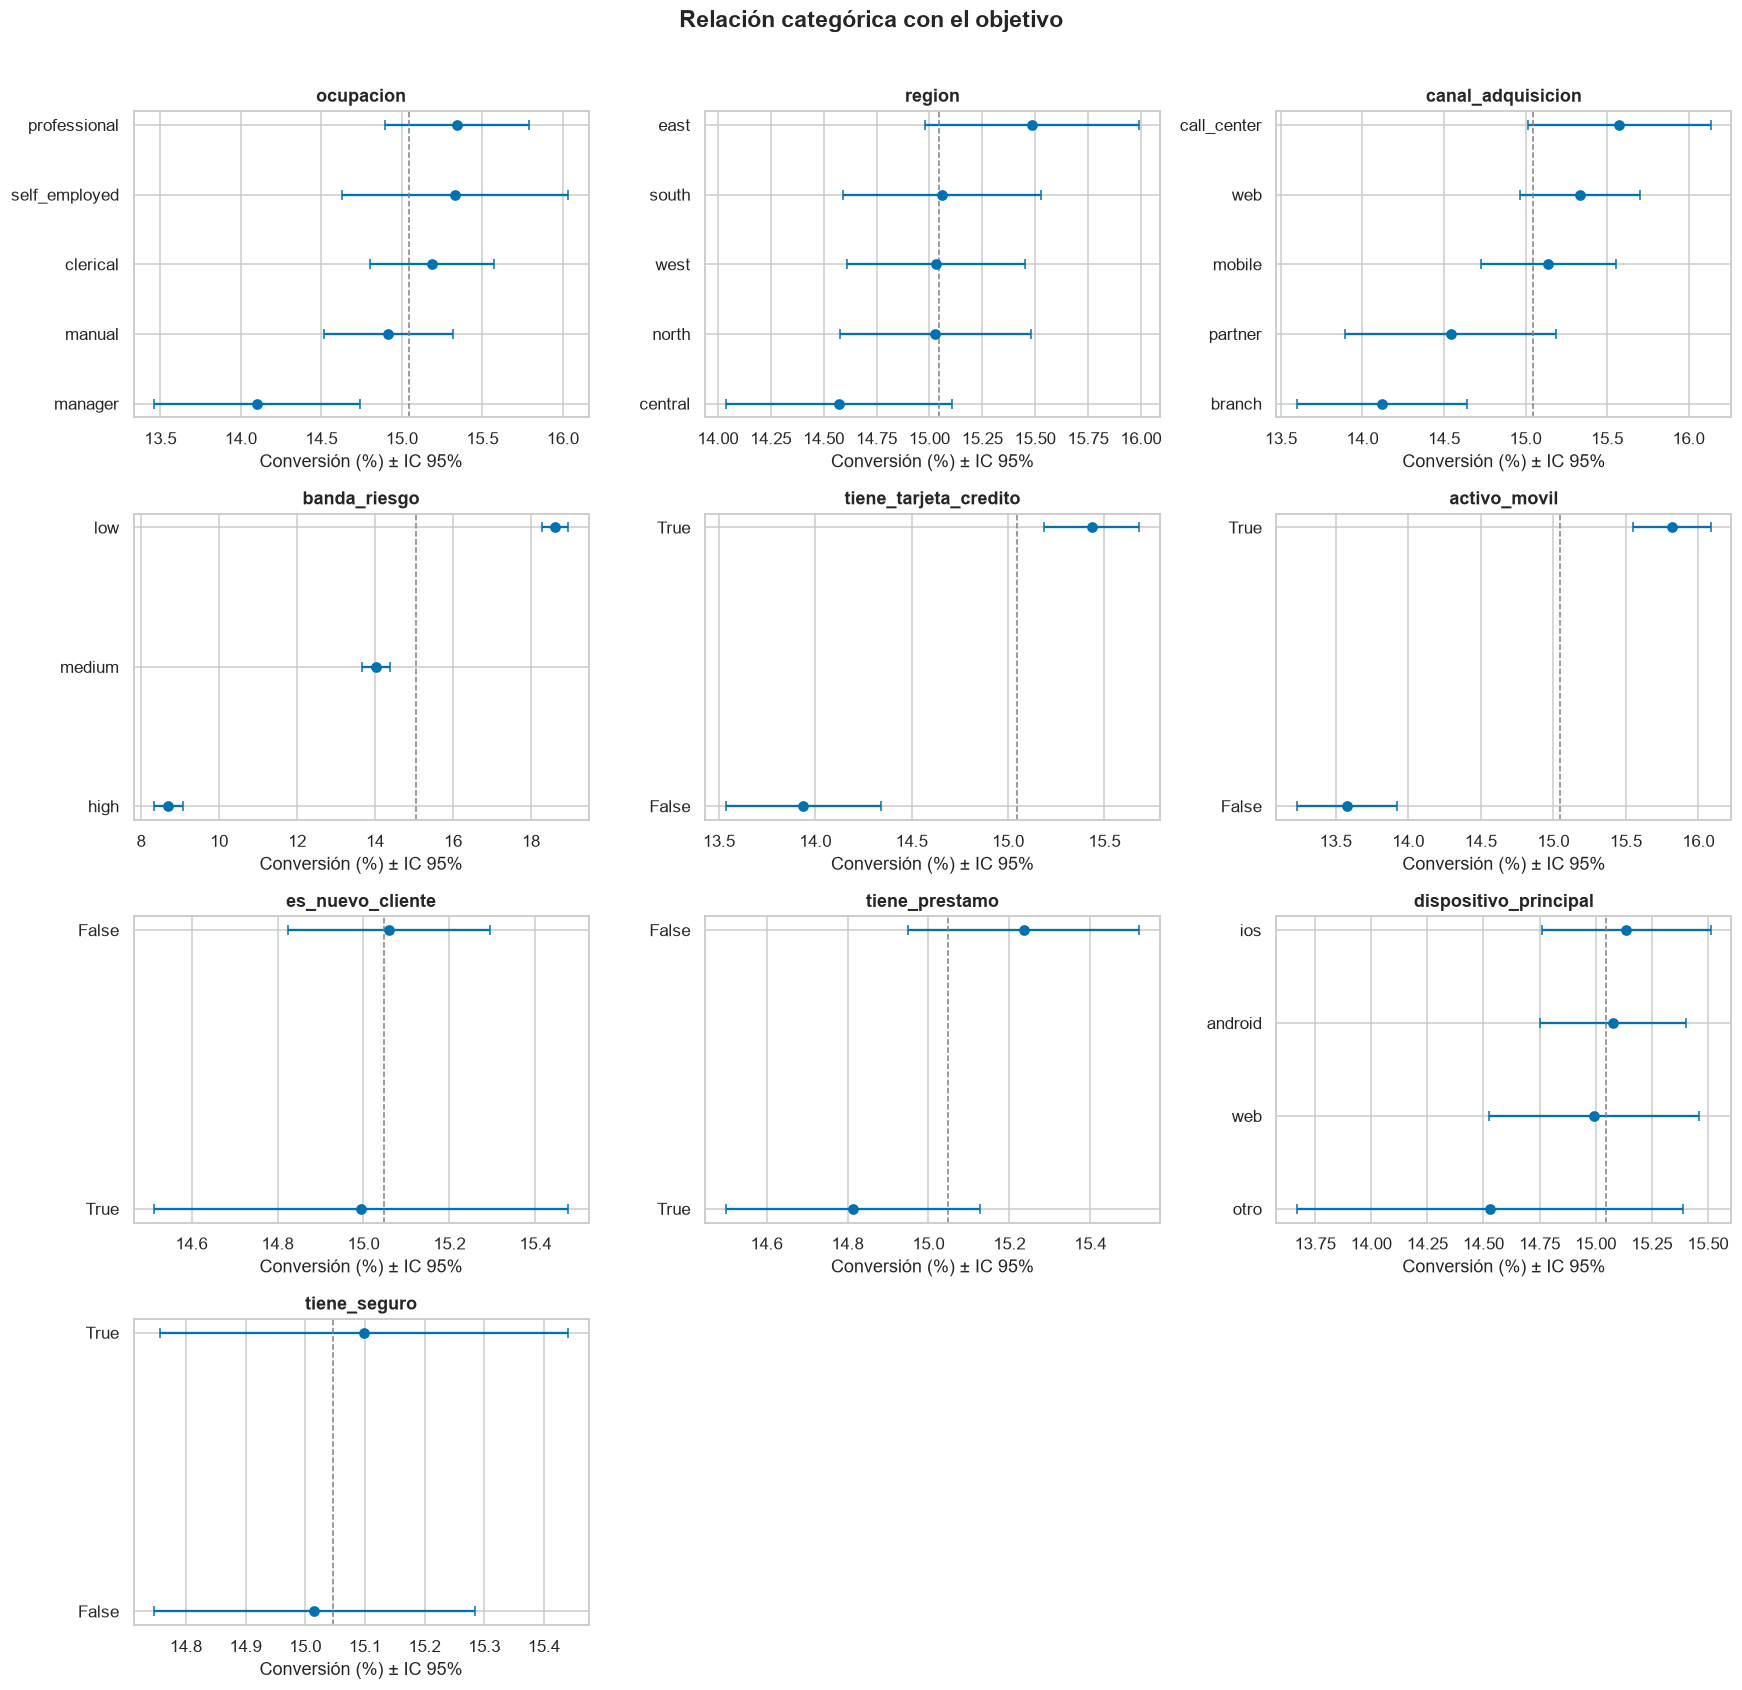

,rango tasa (p.p.)
variable,
banda_riesgo,9.9130
activo_movil,2.2396
tiene_tarjeta_credito,1.4960
canal_adquisicion,1.4550
ocupacion,1.2404
region,0.9125
dispositivo_principal,0.6073
tiene_prestamo,0.4229
tiene_seguro,0.0830


In [20]:
# Tasas por categoría con intervalo normal aproximado de 95% para facilitar lectura.
filas_cat = []
for col in categoricas:
    agg = train.groupby(col, observed=True)["objetivo"].agg(["mean", "size"]).reset_index()
    agg["variable"] = col
    agg["nivel"] = agg[col].astype(str)
    agg["se"] = np.sqrt(agg["mean"] * (1 - agg["mean"]) / agg["size"])
    filas_cat.append(agg[["variable", "nivel", "mean", "size", "se"]])
tasas_cat = pd.concat(filas_cat, ignore_index=True)

fig, axes = plt.subplots(int(np.ceil(len(categoricas) / 3)), 3, figsize=(16, 3.8 * np.ceil(len(categoricas) / 3)))
axes = np.ravel(axes)
for ax, col in zip(axes, categoricas):
    d = tasas_cat.query("variable == @col").sort_values("mean")
    ax.errorbar(d["mean"] * 100, d["nivel"], xerr=1.96 * d["se"] * 100,
                fmt="o", color="#0072B2", capsize=3)
    ax.axvline(global_rate, ls="--", color="grey", lw=1)
    ax.set(title=col, xlabel="Conversión (%) ± IC 95%", ylabel="")
for ax in axes[len(categoricas):]:
    ax.remove()
fig.suptitle("Relación categórica con el objetivo", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

amplitud = tasas_cat.groupby("variable")["mean"].agg(lambda s: 100 * (s.max() - s.min()))
display(amplitud.sort_values(ascending=False).rename("rango tasa (p.p.)").to_frame())

**Señales marginales principales:** `banda_riesgo` destaca claramente (la banda *low* convierte más que *high*, por lo que el nombre se refiere a riesgo crediticio, no a propensión). También aportan `numero_productos`, menor recencia de transacción y `activo_movil`. Muchas variables tienen relaciones casi planas: edad, ingresos, saldo, dirección, visitas web, distancia, día de pago, seguro y cliente nuevo.

## 9. Dinámica del objetivo, exposición y sesgo de cohorte

,size,sum,mean
meses_previos_observados,,,
0,24628,"3,933.0000",0.1597
1,20110,"3,236.0000",0.1609
2,15593,"2,357.0000",0.1512
3,12489,"1,840.0000",0.1473
4,9760,"1,482.0000",0.1518
5,7864,"1,106.0000",0.1406
6,6101,840.0000,0.1377
7,4630,597.0000,0.1289
8,3805,479.0000,0.1259


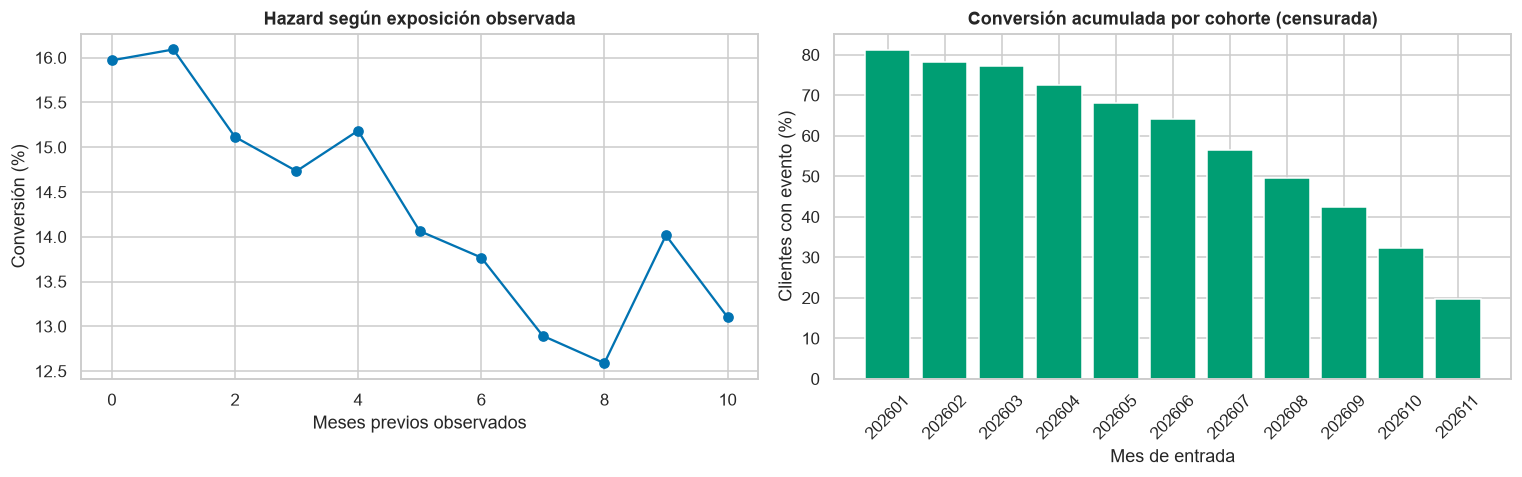

,clientes,eventos,max_meses_previos,conversion_acumulada_observada
primer_mes,,,,
202601,10400,"8,437.0000",11,0.8113
202602,921,720.0000,10,0.7818
202603,2043,"1,578.0000",9,0.7724
202604,827,599.0000,8,0.7243
202605,1973,"1,342.0000",7,0.6802
202606,1834,"1,177.0000",6,0.6418
202607,950,536.0000,5,0.5642
202608,1760,871.0000,4,0.4949
202609,1299,552.0000,3,0.4249


In [21]:
train_panel = panel.loc[panel["_split"].eq("train")].copy()
hazard_exposicion = train_panel.groupby("meses_previos_observados")["objetivo"].agg(["size", "sum", "mean"])
display(hazard_exposicion)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(hazard_exposicion.index, hazard_exposicion["mean"] * 100, marker="o")
axes[0].set(title="Hazard según exposición observada", xlabel="Meses previos observados", ylabel="Conversión (%)")

# Cohortes recientes tienen menor conversión acumulada por menor tiempo de seguimiento.
cohorte = panel.groupby("primer_mes").agg(
    clientes=("id_cliente", "nunique"), eventos=("objetivo", "sum"),
    max_meses_previos=("meses_previos_observados", "max")
)
cohorte["conversion_acumulada_observada"] = cohorte["eventos"] / cohorte["clientes"]
cohorte_train = cohorte.loc[cohorte.index <= 202611]
axes[1].bar(cohorte_train.index.astype(str), cohorte_train["conversion_acumulada_observada"] * 100,
            color="#009E73")
axes[1].set(title="Conversión acumulada por cohorte (censurada)", xlabel="Mes de entrada", ylabel="Clientes con evento (%)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
display(cohorte)

size        sum   mean
mes    es_primera_observacion                         
202601 True                    10400 1,521.0000 0.1462
202602 False                    8879 1,386.0000 0.1561
       True                      921   157.0000 0.1705
202603 False                    8257 1,201.0000 0.1455
       True                     2043   326.0000 0.1596
202604 False                    8773 1,356.0000 0.1546
       True                      827   117.0000 0.1415
202605 False                    8127 1,254.0000 0.1543
       True                     1973   330.0000 0.1673
202606 False                    8516 1,291.0000 0.1516
       True                     1834   309.0000 0.1685
202607 False                    8750 1,248.0000 0.1426
       True                      950   162.0000 0.1705
202608 False                    8290 1,140.0000 0.1375
       True                     1760   309.0000 0.1756
202609 False                    8601 1,175.0000 0.1366
       True                     1299   218.0000 0.1678
202610 False                    8507 1,287.0000 0.1513
       True                     1893   341.0000 0.1801
202611 False                    8772 1,296.0000 0.1477
       True                      728   143.0000 0.1964

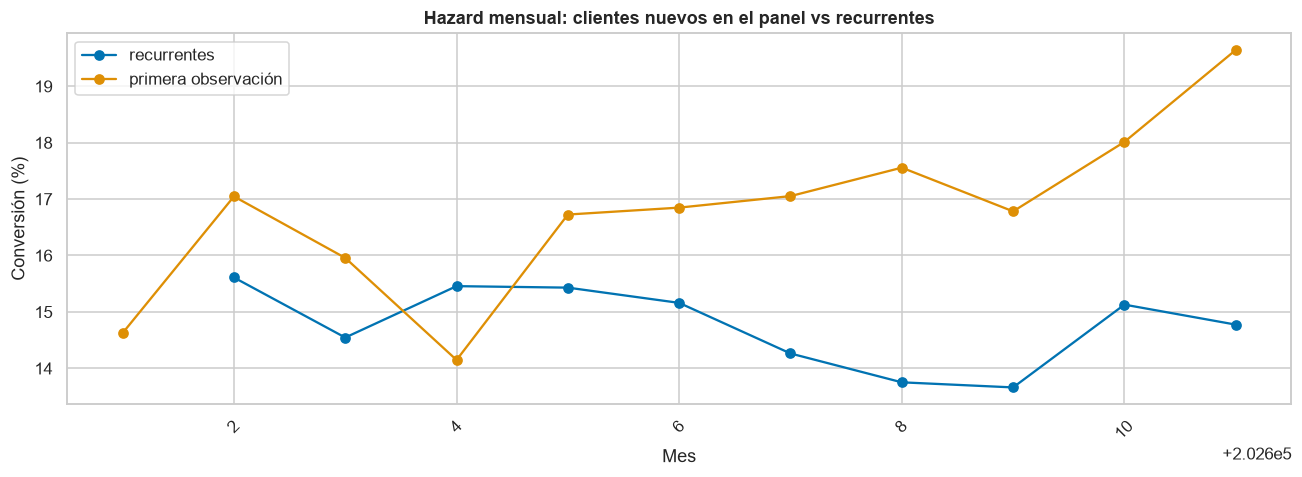

,clientes
meses_previos_observados,
0,1839
1,585
2,1281
3,747
4,889
5,414
6,657
7,631
8,228


In [22]:
# Separar altas nuevas de clientes ya expuestos revela la composición mensual.
nuevos_vs_recurrentes = train_panel.groupby(["mes", "es_primera_observacion"])["objetivo"].agg(["size", "sum", "mean"])
display(nuevos_vs_recurrentes)

plot_nr = nuevos_vs_recurrentes["mean"].unstack().mul(100).rename(columns={False: "recurrentes", True: "primera observación"})
ax = plot_nr.plot(marker="o", figsize=(12, 4.5))
ax.set(title="Hazard mensual: clientes nuevos en el panel vs recurrentes", xlabel="Mes", ylabel="Conversión (%)")
ax.legend(title="")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

composicion_test = panel.loc[panel["_split"].eq("test")].groupby("meses_previos_observados").size().rename("clientes")
display(composicion_test.to_frame())

**Interpretación:** el hazard tiende a caer con la permanencia observada: sobreviven clientes más difíciles de convertir. La conversión acumulada por cohorte no es comparable sin ajustar por seguimiento; las cohortes antiguas han tenido más oportunidades. En diciembre, 1,839 clientes llegan por primera vez y 8,061 son sobrevivientes, una variable de composición crucial.

### 9.1. ¿Cuántos clientes convierten entre quienes tienen M filas?

Cada cliente se cuenta **una sola vez**. Usamos exclusivamente `train` (enero–noviembre),
donde el objetivo es conocido y cada fila corresponde a un mes distinto del cliente.

- **X:** número total de meses observados por cliente, es decir, exactamente M filas.
- **Y:** clientes con al menos un `objetivo = 1` / total de clientes con exactamente M filas.
- Las etiquetas muestran el porcentaje y **convertidos / total de clientes** del grupo.

Es una proporción retrospectiva por duración final observada, **no** el hazard en el mes M
(cuyo denominador serían todos los clientes aún en riesgo al llegar a ese mes).


,clientes,convertidos,sin_conversion_observada,ratio_conversion
n_meses,,,,
1,"4,518","3,933",585,87.1%
2,"4,517","3,236","1,281",71.6%
3,"3,104","2,357",747,75.9%
4,"2,729","1,840",889,67.4%
5,"1,896","1,482",414,78.2%
6,"1,763","1,106",657,62.7%
7,"1,471",840,631,57.1%
8,825,597,228,72.4%
9,944,479,465,50.7%


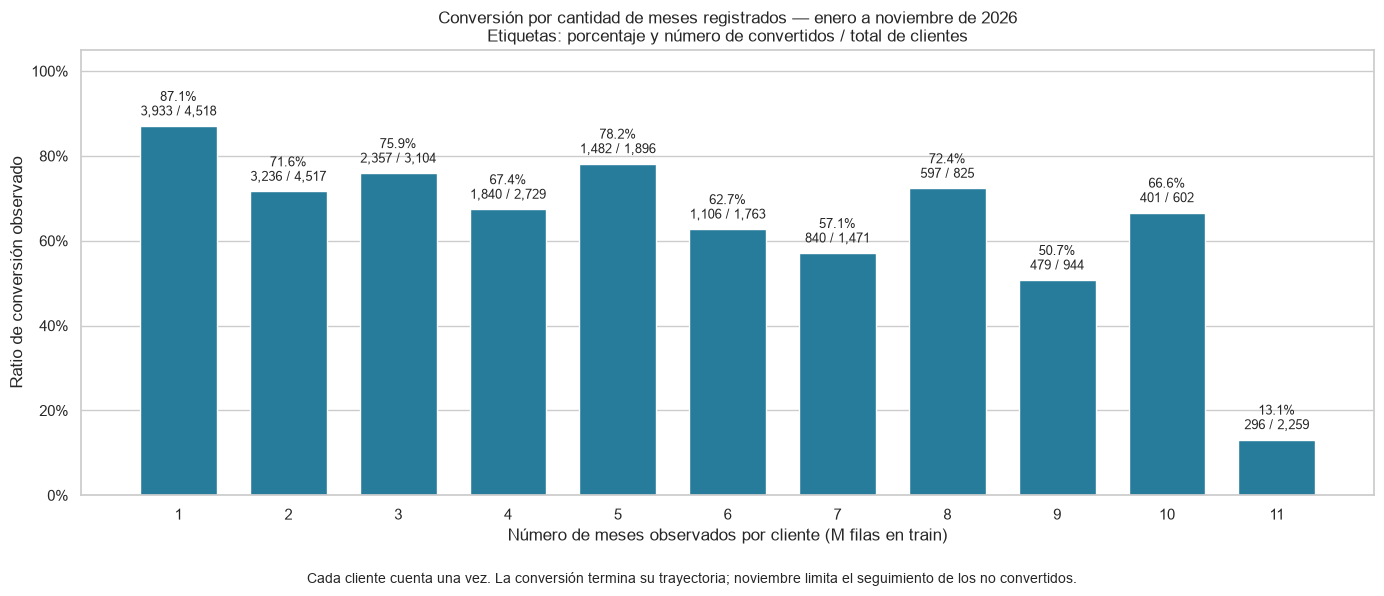

In [1]:
# Agregamos primero por cliente para no contar varias veces a una persona.
from matplotlib.ticker import PercentFormatter

assert not train.duplicated(["id_cliente", "mes"]).any()
assert train["objetivo"].isin([0, 1]).all()
conversion_por_cliente = train.groupby("id_cliente").agg(
    n_meses=("mes", "size"),
    convirtio=("objetivo", "max"),
)
conversion_por_meses = conversion_por_cliente.groupby("n_meses").agg(
    clientes=("convirtio", "size"),
    convertidos=("convirtio", "sum"),
    ratio_conversion=("convirtio", "mean"),
)
conversion_por_meses["sin_conversion_observada"] = (
    conversion_por_meses["clientes"] - conversion_por_meses["convertidos"]
)
conversion_por_meses = conversion_por_meses[
    ["clientes", "convertidos", "sin_conversion_observada", "ratio_conversion"]
]
assert conversion_por_meses["clientes"].sum() == train["id_cliente"].nunique()
assert conversion_por_meses["convertidos"].sum() == conversion_por_cliente["convirtio"].sum()
display(conversion_por_meses.style.format({
    "clientes": "{:,.0f}", "convertidos": "{:,.0f}",
    "sin_conversion_observada": "{:,.0f}", "ratio_conversion": "{:.1%}",
}))

# El eje parte de cero y las etiquetas incluyen numerador y denominador.
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(conversion_por_meses.index, conversion_por_meses["ratio_conversion"],
       color="#287C9B", width=0.70)
for meses, fila in conversion_por_meses.iterrows():
    etiqueta = (f"{fila['ratio_conversion']:.1%}\n"
                f"{int(fila['convertidos']):,} / {int(fila['clientes']):,}")
    ax.annotate(etiqueta, (meses, fila["ratio_conversion"]),
                xytext=(0, 5), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)
ax.set(xticks=conversion_por_meses.index, ylim=(0, 1.05),
       xlabel="Número de meses observados por cliente (M filas en train)",
       ylabel="Ratio de conversión observado",
       title="Conversión por cantidad de meses registrados — enero a noviembre de 2026\n"
             "Etiquetas: porcentaje y número de convertidos / total de clientes")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
fig.text(0.5, 0.015,
         "Cada cliente cuenta una vez. La conversión termina su trayectoria; "
         "noviembre limita el seguimiento de los no convertidos.",
         ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


**Lectura:** entre los clientes con una fila, convirtieron **3.933 / 4.518
(87,1%)**; entre quienes tienen once filas, **296 / 2.259 (13,1%)**. La relación no es
monótona: por ejemplo, sube de 67,4% con cuatro filas a 78,2% con cinco.

**Cuidado con la interpretación:** los clientes dejan de aparecer al convertir, mientras
que quienes no convierten quedan censurados al terminar noviembre. Por eso, el grupo de
once filas concentra sobrevivientes observados desde enero (1.963 sin conversión observada).
Un cliente con una fila, en cambio, puede ser alguien que convirtió inmediatamente o alguien
que ingresó en noviembre sin convertir. Se mezclan distintas cohortes y oportunidades de
seguimiento: el gráfico no demuestra que observar más meses reduzca la propensión a convertir,
ni estima la probabilidad de convertir antes de M meses.

La cantidad **final** de filas usa información futura y del desenlace: sirve para esta
descripción retrospectiva, **no como predictor** de una conversión futura. Tampoco se deben
interpretar los clientes sin conversión observada como clientes que nunca convertirán.


### 9.2. ¿Qué porcentaje del total convirtió en su mes observado M?

Aquí el denominador es **el total de clientes únicos de train**, igual para todas las
barras; a diferencia del gráfico anterior, no se condiciona a tener exactamente M filas.
Cada cliente pertenece a una sola categoría: convirtió en M = 1, 2, …, 11, o no tuvo
conversión observada hasta noviembre. **Todas las categorías suman 100%.**

Interpretamos «después de M meses» como **en el M-ésimo mes desde su primera observación**:
M = 1 es el propio mes de entrada al panel (no un mes completo transcurrido), M = 2 el
siguiente, etc. No es el mes calendario, ni el tiempo desde abrir la cuenta. Tampoco es
una distribución acumulada: la barra M contiene solo conversiones ocurridas en ese mes.


,clientes,porcentaje_del_total
resultado,,
Convirtió en mes 1,"3,933",15.97%
Convirtió en mes 2,"3,236",13.14%
Convirtió en mes 3,"2,357",9.57%
Convirtió en mes 4,"1,840",7.47%
Convirtió en mes 5,"1,482",6.02%
Convirtió en mes 6,"1,106",4.49%
Convirtió en mes 7,840,3.41%
Convirtió en mes 8,597,2.42%
Convirtió en mes 9,479,1.94%


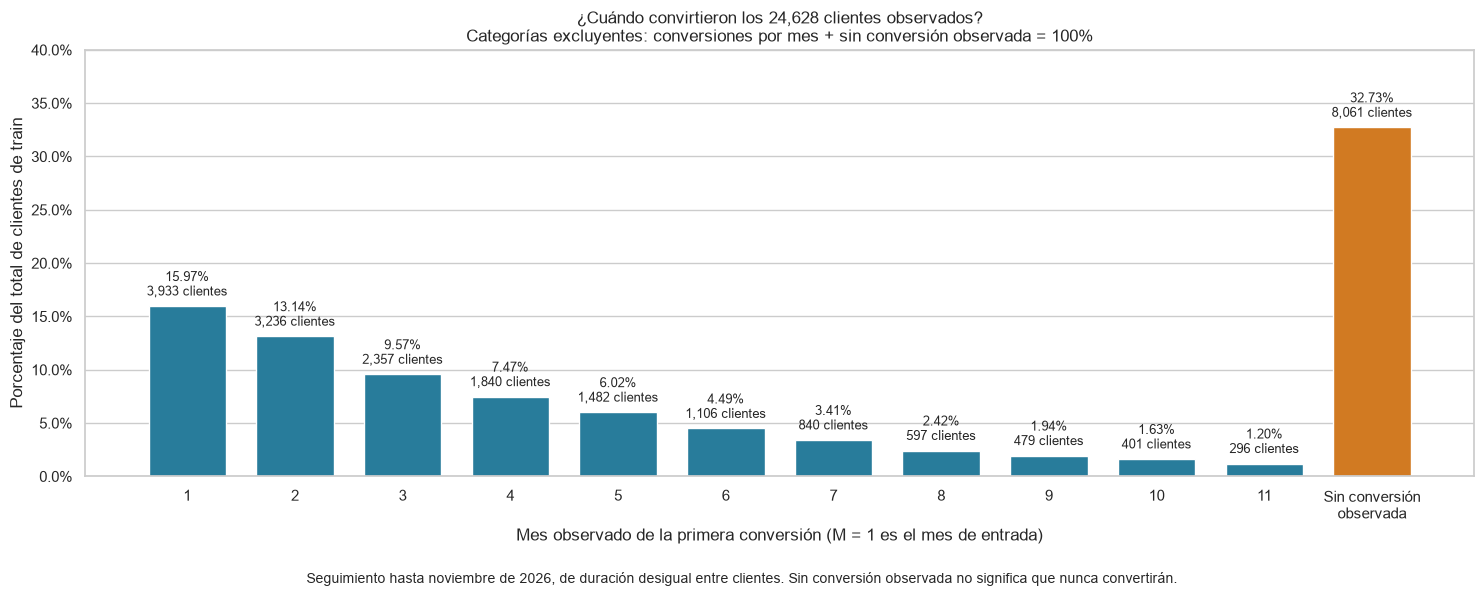

In [1]:
from matplotlib.ticker import PercentFormatter

# Calculamos el tiempo relativo a la primera observación de cada cliente.
# No añadimos diciembre: test no tiene etiqueta de conversión.
panel_momento = train[["id_cliente", "mes", "objetivo"]].copy()
assert not panel_momento.duplicated(["id_cliente", "mes"]).any()
assert panel_momento["objetivo"].isin([0, 1]).all()
fecha_momento = pd.to_datetime(panel_momento["mes"].astype(str), format="%Y%m")
mes_absoluto = fecha_momento.dt.year * 12 + fecha_momento.dt.month
panel_momento["mes_observado"] = (
    mes_absoluto - mes_absoluto.groupby(panel_momento["id_cliente"]).transform("min") + 1
)
clientes_momento = panel_momento.groupby("id_cliente").agg(
    n_filas=("mes", "size"), ultimo_mes=("mes_observado", "max"),
    n_conversiones=("objetivo", "sum"),
)
# Comprobamos las propiedades del panel antes de interpretar los tiempos.
assert clientes_momento["n_filas"].eq(clientes_momento["ultimo_mes"]).all()
assert clientes_momento["n_conversiones"].le(1).all()
eventos_momento = panel_momento.loc[panel_momento["objetivo"].eq(1)]
assert eventos_momento["mes_observado"].eq(
    eventos_momento["id_cliente"].map(clientes_momento["ultimo_mes"])
).all()

# Usamos el mismo denominador para todas las barras y una categoría de censura.
total_clientes_momento = len(clientes_momento)
meses_momento = range(1, int(clientes_momento["ultimo_mes"].max()) + 1)
conteos_momento = eventos_momento["mes_observado"].value_counts().reindex(
    meses_momento, fill_value=0
).sort_index()
sin_conversion_momento = int(clientes_momento["n_conversiones"].eq(0).sum())
distribucion_momento = pd.DataFrame({
    "resultado": [f"Convirtió en mes {m}" for m in meses_momento]
                 + ["Sin conversión observada hasta noviembre"],
    "clientes": conteos_momento.tolist() + [sin_conversion_momento],
})
distribucion_momento["porcentaje_del_total"] = (
    distribucion_momento["clientes"] / total_clientes_momento
)
assert distribucion_momento["clientes"].sum() == total_clientes_momento
assert abs(distribucion_momento["porcentaje_del_total"].sum() - 1) < 1e-12
display(distribucion_momento.set_index("resultado").style.format({
    "clientes": "{:,.0f}", "porcentaje_del_total": "{:.2%}",
}))

fig, ax = plt.subplots(figsize=(15, 6))
x_momento = list(range(len(distribucion_momento)))
ax.bar(x_momento, distribucion_momento["porcentaje_del_total"], width=0.72,
       color=["#287C9B"] * len(conteos_momento) + ["#D17A22"])
for x, fila in distribucion_momento.iterrows():
    ax.annotate(f"{fila['porcentaje_del_total']:.2%}\n{int(fila['clientes']):,} clientes",
                (x, fila["porcentaje_del_total"]), xytext=(0, 5),
                textcoords="offset points", ha="center", va="bottom", fontsize=9)
ax.set(xticks=x_momento,
       xticklabels=[str(m) for m in meses_momento] + ["Sin conversión\nobservada"],
       ylim=(0, 0.40), xlabel="Mes observado de la primera conversión (M = 1 es el mes de entrada)",
       ylabel="Porcentaje del total de clientes de train",
       title=f"¿Cuándo convirtieron los {total_clientes_momento:,} clientes observados?\n"
             "Categorías excluyentes: conversiones por mes + sin conversión observada = 100%")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
fig.text(0.5, 0.015,
         "Seguimiento hasta noviembre de 2026, de duración desigual entre clientes. "
         "Sin conversión observada no significa que nunca convertirán.",
         ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


**Lectura:** de los **24.628 clientes**, **16.567 (67,27%)** convirtieron
durante el periodo observado y **8.061 (32,73%)** no tuvieron una conversión registrada.
El primer mes reúne **3.933 conversiones (15,97% del total)**; el segundo, **3.236
(13,14%)**. Estos porcentajes no son las tasas condicionadas por duración del gráfico 9.1,
ni las tasas entre clientes aún en riesgo.

**Límite de la lectura:** no todos tuvieron once meses para convertir. Las cohortes más
recientes tienen menor seguimiento y no pueden aportar eventos a los meses relativos
más tardíos. Por eso, esta es la distribución de los desenlaces **observados**, sin ajuste
por censura; la caída de las barras no demuestra por sí sola que el hazard disminuya.
La última barra incluye clientes censurados, no clientes que sabemos que nunca convertirán.


## 10. Estabilidad temporal de las señales

mes,202601,202602,202603,202604,202605,202606,202607,202608,202609,202610,202611
variable,,,,,,,,,,,
activo_movil,0.5272,0.5246,0.5228,0.5219,0.5269,0.5112,0.5033,0.5296,0.5188,0.5147,0.5159
banda_riesgo,0.5720,0.5835,0.5805,0.5827,0.5836,0.5741,0.5854,0.5845,0.5781,0.5790,0.5704
dias_ultima_interaccion,0.4619,0.4634,0.4535,0.4643,0.4684,0.4772,0.4672,0.4822,0.4797,0.4736,0.4913
dias_ultima_transaccion,0.4619,0.4696,0.4410,0.4526,0.4591,0.4533,0.4437,0.4492,0.4449,0.4612,0.4507
id_cliente,0.4972,0.5008,0.5113,0.5093,0.5104,0.5202,0.5350,0.5403,0.5286,0.5372,0.5367
numero_productos,0.5769,0.5652,0.5523,0.5557,0.5612,0.5592,0.5575,0.5454,0.5524,0.5645,0.5312


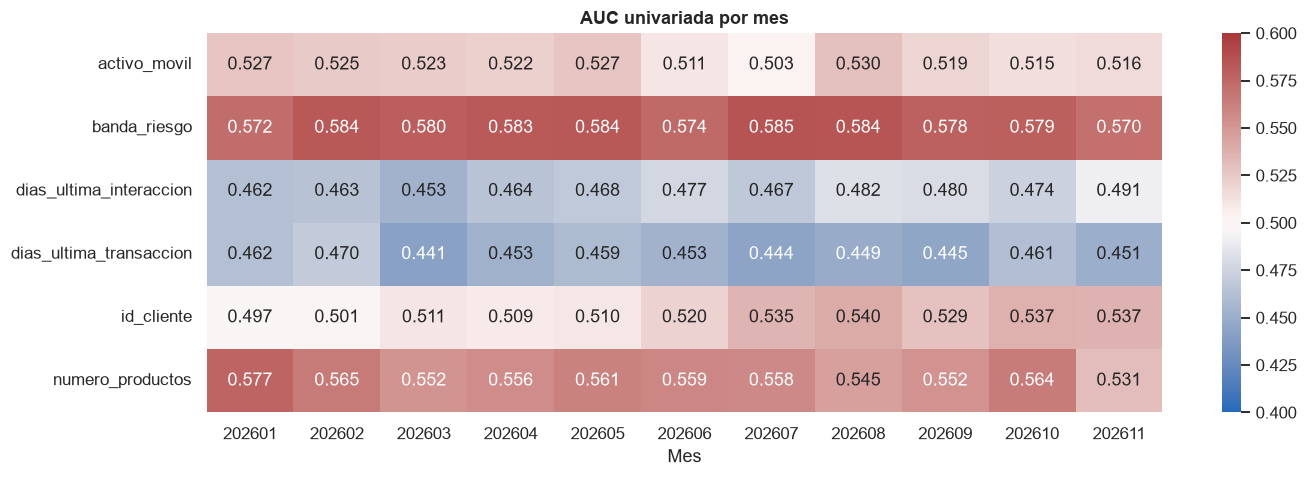

In [23]:
# AUC univariada mensual. Para categorías se usa el orden global de tasas calculado solo en train.
variables_auc = [
    "banda_riesgo", "numero_productos", "dias_ultima_transaccion",
    "dias_ultima_interaccion", "activo_movil", "id_cliente"
]
auc_rows = []
for col in variables_auc:
    global_order = train.groupby(col, observed=True)["objetivo"].mean() if train[col].dtype == "object" else None
    for mes, d in train.groupby("mes"):
        score = d[col].map(global_order) if global_order is not None else d[col].astype(float)
        auc_rows.append({"variable": col, "mes": mes, "AUC": roc_auc_score(d["objetivo"], score)})
auc_mes = pd.DataFrame(auc_rows).pivot(index="variable", columns="mes", values="AUC")
display(auc_mes)

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(auc_mes, cmap="vlag", center=.5, vmin=.4, vmax=.6, annot=True, fmt=".3f", ax=ax)
ax.set(title="AUC univariada por mes", xlabel="Mes", ylabel="")
plt.tight_layout()
plt.show()

La dirección de las señales principales es estable. `id_cliente` gana AUC en meses recientes porque los IDs codifican el orden de alta/cohorte; usarlo directamente sería una apuesta frágil contra el mecanismo de generación. Es preferible expresar esa información como cohorte o meses de exposición, y validarla fuera de tiempo.

## 11. Drift entre entrenamiento y diciembre

,variable,tipo,métrica,valor,SMD
10,banda_riesgo,discreta,TV,0.0373,NaN
6,dias_ultima_transaccion,numérica,KS,0.0221,0.0388
21,dias_ultima_interaccion,numérica,KS,0.0221,0.0396
4,numero_productos,numérica,KS,0.0211,-0.0485
2,ratio_deuda_ingresos,numérica,KS,0.0111,0.0180
12,activo_movil,discreta,TV,0.0093,NaN
8,region,discreta,TV,0.0087,NaN
18,dispositivo_principal,discreta,TV,0.0087,NaN
1,ingresos,numérica,KS,0.0083,0.0083
9,canal_adquisicion,discreta,TV,0.0075,NaN


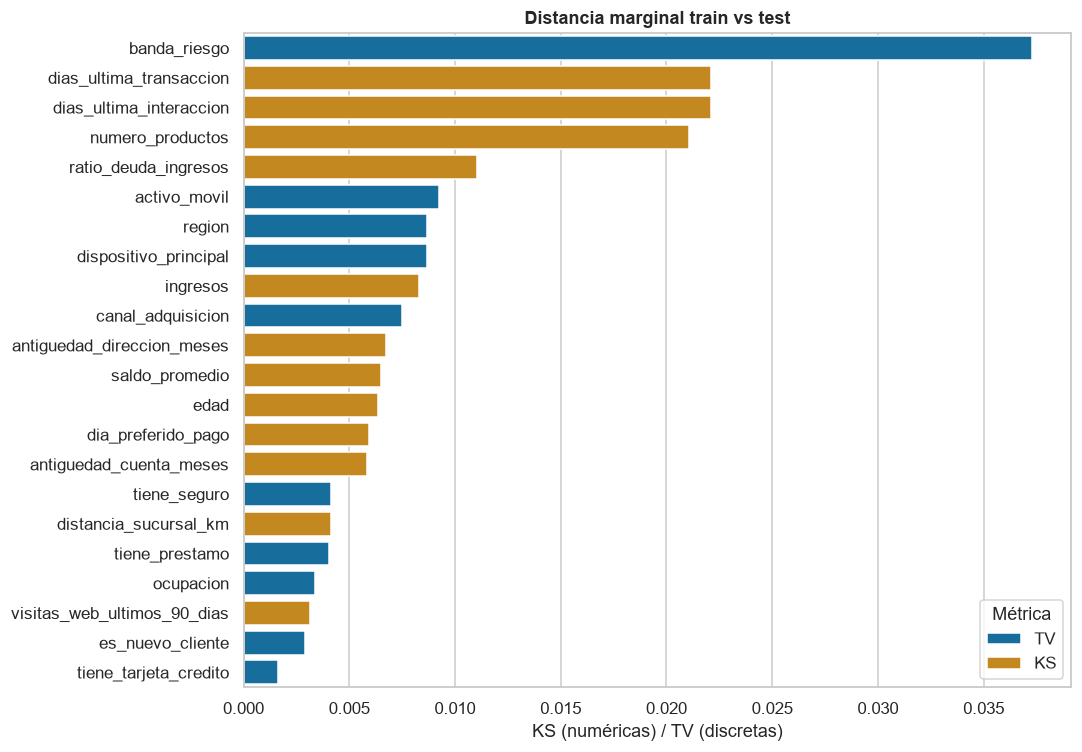

In [24]:
# KS para numéricas y distancia de variación total (TV) para discretas.
drift = []
for col in predictores:
    if pd.api.types.is_numeric_dtype(train[col]) and not pd.api.types.is_bool_dtype(train[col]):
        stat = ks_2samp(train[col], test[col]).statistic
        pooled_sd = np.sqrt((train[col].var() + test[col].var()) / 2)
        smd = (test[col].mean() - train[col].mean()) / pooled_sd if pooled_sd else 0
        drift.append({"variable": col, "tipo": "numérica", "métrica": "KS", "valor": stat, "SMD": smd})
    else:
        p = train[col].astype(str).value_counts(normalize=True)
        q = test[col].astype(str).value_counts(normalize=True)
        idx = p.index.union(q.index)
        tv = .5 * (p.reindex(idx, fill_value=0) - q.reindex(idx, fill_value=0)).abs().sum()
        drift.append({"variable": col, "tipo": "discreta", "métrica": "TV", "valor": tv, "SMD": np.nan})
drift = pd.DataFrame(drift).sort_values("valor", ascending=False)
display(drift)

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=drift, y="variable", x="valor", hue="métrica", dodge=False, ax=ax)
ax.set(title="Distancia marginal train vs test", xlabel="KS (numéricas) / TV (discretas)", ylabel="")
ax.legend(title="Métrica")
plt.tight_layout()
plt.show()

El drift marginal es pequeño. El mayor cambio discreto está en `banda_riesgo`, pero sigue siendo moderado. Esto no elimina el cambio de composición por exposición: los histogramas marginales pueden parecer estables mientras cambia la mezcla de cohortes y sobrevivientes.

## 12. Estados repetidos, etiquetas contradictorias y riesgo de fuga

,definición de estado,grupos repetidos,grupos con etiquetas 0 y 1,filas en grupos contradictorios
0,todos los predictores,14360,6060,20412
1,sin interacción dinámica,20110,12634,57182


,meses por cliente
count,"24,628.0000"
mean,4.4705
std,3.1716
min,1.0000
25%,2.0000
50%,4.0000
75%,6.0000
max,11.0000


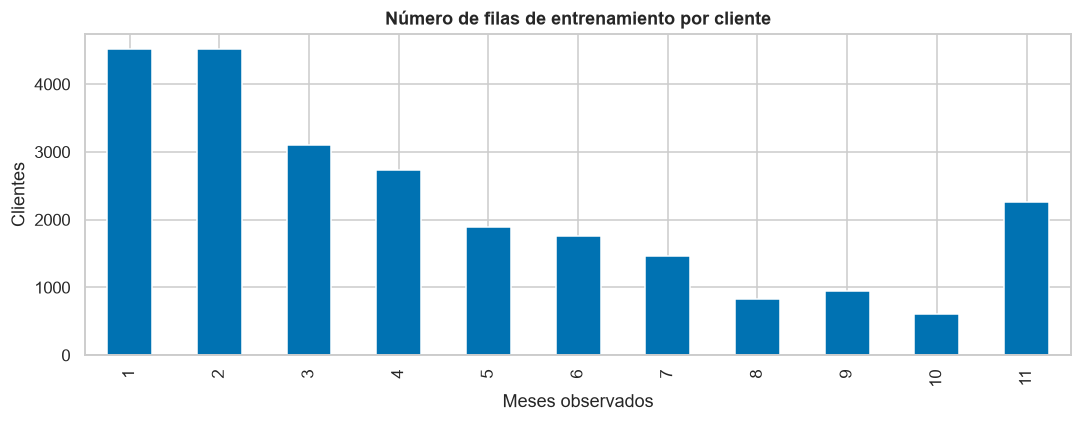

In [25]:
# Un mismo estado fijo puede tener ceros en meses previos y un uno en el mes del evento.
fijas = [c for c in predictores if c != "dias_ultima_interaccion"]
resultados_estado = []
for nombre, columnas in {
    "todos los predictores": predictores,
    "sin interacción dinámica": fijas,
}.items():
    grupos = train.groupby(["id_cliente"] + columnas, dropna=False)["objetivo"].agg(["size", "nunique"])
    conflicto = grupos["nunique"].gt(1)
    resultados_estado.append({
        "definición de estado": nombre,
        "grupos repetidos": int(grupos["size"].gt(1).sum()),
        "grupos con etiquetas 0 y 1": int(conflicto.sum()),
        "filas en grupos contradictorios": int(grupos.loc[conflicto, "size"].sum()),
    })
display(pd.DataFrame(resultados_estado))

# Cuántos meses aporta cada cliente: explica por qué un split aleatorio filtra identidades.
meses_cliente = train.groupby("id_cliente").size()
display(meses_cliente.describe().rename("meses por cliente").to_frame())
ax = meses_cliente.value_counts().sort_index().plot.bar(figsize=(10, 4), color="#0072B2")
ax.set(title="Número de filas de entrenamiento por cliente", xlabel="Meses observados", ylabel="Clientes")
plt.tight_layout()
plt.show()

### Implicaciones para modelado y validación

1. **No usar split aleatorio por filas.** El mismo cliente y casi todos sus atributos aparecerían en train y validación; además se usarían meses futuros para predecir el pasado.
2. **Validación primaria:** entrenar con enero–octubre y validar noviembre; como robustez, hacer backtesting expansivo (validar ago, sep, oct y nov).
3. **Objetivo correcto:** probabilidad mensual condicionada a no haber convertido antes. No balancear clases indiscriminadamente: alteraría la probabilidad base y su calibración.
4. **Features longitudinales seguras:** meses previos observados, mes/cohorte, indicador de primera observación, último valor y cambio de `dias_ultima_interaccion`. Todo debe calcularse usando únicamente información disponible hasta el corte.
5. **Excluir o regularizar `id_cliente`.** Es identificador y proxy de cohorte; su aparente señal puede no generalizar a IDs futuros.
6. **Variables congeladas:** no interpretar como mediciones mensuales reales ni crear tendencias ficticias. Pedir al dueño de datos si son snapshots de alta, imputaciones “forward fill” o un artefacto sintético.
7. **Evaluación:** AUC/Gini mide ranking, pero conviene revisar AUC por nuevos/recurrentes y por cohorte. Si se necesitan probabilidades, añadir Brier/calibración temporal.

## 13. Conclusiones ejecutivas

In [26]:
# Cifras finales calculadas para que la conclusión permanezca sincronizada con los datos.
tasa = train["objetivo"].mean()
frozen = consistencia.loc[consistencia["% exactamente igual"].eq(100), "variable"].tolist()
new_test = len(clientes_test - clientes_train)
old_test = len(clientes_test & clientes_train)
band_rates = train.groupby("banda_riesgo")["objetivo"].mean().sort_values()

display(Markdown(f'''
- El dataset tiene **{len(train):,} filas**, **{train['id_cliente'].nunique():,} clientes** en train y cero faltantes o llaves duplicadas.
- La tasa fila–mes es **{tasa:.2%}**; hubo **{int(train['objetivo'].sum()):,}** primeros eventos y se respeta completamente la salida posterior a conversión.
- **{len(frozen)} de {len(predictores)} predictores** nunca cambian entre meses consecutivos del mismo cliente. La excepción es `dias_ultima_interaccion`.
- Diciembre mezcla **{old_test:,} sobrevivientes** y **{new_test:,} clientes nuevos**. La exposición previa debe entrar explícitamente al modelo.
- `banda_riesgo` es la señal marginal más clara: la tasa va de **{band_rates.iloc[0]:.2%}** a **{band_rates.iloc[-1]:.2%}**, con sentido inverso al nombre si se interpreta como propensión.
- La calidad estructural es alta, pero la coherencia temporal es artificial. El principal riesgo no son los nulos: es validar como i.i.d. un panel censurado y casi estático.
'''))


- El dataset tiene **110,100 filas**, **24,628 clientes** en train y cero faltantes o llaves duplicadas.
- La tasa fila–mes es **15.05%**; hubo **16,567** primeros eventos y se respeta completamente la salida posterior a conversión.
- **21 de 22 predictores** nunca cambian entre meses consecutivos del mismo cliente. La excepción es `dias_ultima_interaccion`.
- Diciembre mezcla **8,061 sobrevivientes** y **1,839 clientes nuevos**. La exposición previa debe entrar explícitamente al modelo.
- `banda_riesgo` es la señal marginal más clara: la tasa va de **8.70%** a **18.61%**, con sentido inverso al nombre si se interpreta como propensión.
- La calidad estructural es alta, pero la coherencia temporal es artificial. El principal riesgo no son los nulos: es validar como i.i.d. un panel censurado y casi estático.
